# Práctica: Regresión Lineal, Regresión Polinomial, SVR, Ensambles (AdaBoost, Gradient Boosting, Stacking y Voting), XGBoost — Load Shedding en la red eléctrica de Bangladesh

#### Universidad Autónoma de Chihuahua | Facultad de Ingeniería | Maestría en Ciencias de la Computación
#### Materia: Machine Learning
#### Actividad: Métodos de regresión para la predicción de variables continuas
#### Catedrático: Dra. Olanda Prieto Ordaz
#### Nombre Alumno: Andrea Georgina Rodríguez Pacheco
#### Matrícula: 395699
#### Fecha: 1 de noviembre de 2026

# I. Introducción

- **Dataset:** PGCB Hourly Generation Dataset (Bangladesh), UCI Machine Learning Repository, complementado con clima horario de Open-Meteo.
- **Problema:** predecir el *load shedding* horario (MW). Variable objetivo `load_shedding`, problema de **regresión** supervisada.
- **Punto de partida:** `LoadSheddingSVR.ipynb`. Se reutilizan sin cambios la limpieza, la partición temporal, el EDA, el Pipeline de preprocesamiento y los folds de `TimeSeriesSplit`, para que los resultados sean comparables con el SVR RBF optimizado (C = 100, γ = 0.01).
- **Objetivo de la práctica:** comparar en un mismo flujo todos los modelos de regresión del curso:
  - **Modelos lineales:** `LinearRegression`, `Ridge` y regresión polinomial (`PolynomialFeatures` + `Ridge`).
  - **SVR:** kernels lineal, polinomial y RBF, con el RBF optimizado por `GridSearchCV`.
  - **Ensambles:**
    - **AdaBoost:** *boosting* que reajusta los pesos de las muestras según el error del árbol anterior.
    - **Gradient Boosting:** *boosting* que ajusta cada árbol nuevo a los residuos (gradiente negativo de la pérdida) del ensamble actual.
    - **Stacking:** combina las predicciones de varios modelos base mediante un meta-modelo.
    - **Voting:** combina las predicciones de varios modelos base sin meta-modelo: *soft* (media, con o sin pesos) y *hard* (mediana).

Flujo: Datos → Inspección inicial → X/y → Train/Test → EDA solo en Train → Pipeline → Cross-Validation → Modelos lineales → SVR → Ensambles → Comparación de modelos → Optimización → Stacking → Voting → Test final.

In [1]:
import os
import time
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, StackingRegressor, VotingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, TimeSeriesSplit, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

RANDOM_STATE = 42
warnings.filterwarnings("ignore", category=FutureWarning)

# III. Preparación de los datos

## Fase 1. Selección y preparación de los datos

### 1. Selección del problema
**Regresión — Load shedding (PGCB, Bangladesh).** La variable objetivo es numérica y continua (`load_shedding`, MW) y los datos son horarios, igual que en la opción B.

### 2. Inspección inicial
Dimensiones, tipos de variables, valores faltantes, duplicados y variable objetivo. En esta etapa no se realizan transformaciones dependientes de los datos.

In [2]:
zip_path = "../pgcb+hourly+generation+dataset+(bangladesh).zip"

with zipfile.ZipFile(zip_path) as z:
    X = pd.read_excel(z.open("PGCB_date_power_demand.xlsx"))

TARGET = "load_shedding"

X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92650 entries, 0 to 92649
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   datetime              92650 non-null  datetime64[ns]
 1   generation_mw         92650 non-null  float64       
 2   demand_mw             92650 non-null  int64         
 3   load_shedding         92650 non-null  int64         
 4   gas                   92650 non-null  int64         
 5   liquid_fuel           92650 non-null  int64         
 6   coal                  92650 non-null  int64         
 7   hydro                 92650 non-null  int64         
 8   solar                 70517 non-null  float64       
 9   wind                  18676 non-null  float64       
 10  india_bheramara_hvdc  92650 non-null  int64         
 11  india_tripura         92650 non-null  int64         
 12  india_adani           7338 non-null   float64       
 13  nepal           

In [3]:
border = "-" * 40
print("Dimensiones:", X.shape)
print(border)
print("Valores faltantes")
missing = X.isnull().sum()
print(pd.DataFrame({"faltantes": missing, "%": (missing / len(X) * 100).round(1)})[missing > 0].to_string())
print(border)
print("Registros duplicados completos:", X.duplicated().sum())
print("Marcas de tiempo repetidas:", X["datetime"].duplicated().sum())
print(border)
print(f"Rango de {TARGET}: {X[TARGET].min()} → {X[TARGET].max()}")
print(border)
print("Resumen estadístico (variables numéricas)")
print(X.describe().round(2).to_string())

Dimensiones: (92650, 15)
----------------------------------------
Valores faltantes
             faltantes     %
solar            22133  23.9
wind             73974  79.8
india_adani      85312  92.1
nepal            87299  94.2
remarks          86257  93.1
----------------------------------------
Registros duplicados completos: 160
Marcas de tiempo repetidas: 432
----------------------------------------
Rango de load_shedding: 0 → 65359
----------------------------------------
Resumen estadístico (variables numéricas)
                            datetime  generation_mw  demand_mw  load_shedding       gas  liquid_fuel      coal     hydro     solar      wind  india_bheramara_hvdc  india_tripura  india_adani    nepal
count                          92650       92650.00   92650.00       92650.00  92650.00     92650.00  92650.00  92650.00  70517.00  18676.00              92650.00       92650.00      7338.00  5351.00
mean   2020-05-17 03:52:07.609282304        9429.38    8819.65          81.

### Observaciones
- **Tamaño:** 92,650 registros y 15 columnas (2015-04 a 2025-06).
- **Tipos:** 13 numéricas, `remarks` categórica (`Day_Peak`, `Evening_Peak`) y `datetime` de tipo fecha.
- **Faltantes:** se concentran en fuentes que empezaron a registrarse tarde (`nepal` 94.2%, `remarks` 93.1%, `india_adani` 92.1%, `wind` 79.8%, `solar` 23.9%).
- **Duplicados:** 160 registros completos y 432 marcas de tiempo repetidas.
- **Valores imposibles:** `load_shedding` = 65,359 MW o `generation_mw` = 64,526,500 MW, muy por encima de la capacidad de la red (< 17,000 MW).
- **Variable objetivo:** `load_shedding`, numérica continua; la mediana del histórico completo es 0.

## Fase 2. Partición y EDA

### 3. Definición de X e y

X = variables predictoras, y = `load_shedding`.

**Limpieza previa a la partición** (reglas fijas, no calculadas con los datos, por lo que no generan fuga de información):
- Eliminación de duplicados y de marcas de tiempo repetidas (un mismo registro en Train y Test sería fuga).
- Orden cronológico (el archivo viene en orden descendente).
- Eliminación de valores físicamente imposibles (p. ej. `generation_mw` = 64,526,500), con límites basados en la capacidad de la red.
- **Periodo de estudio:** últimos tres años (desde junio de 2022). Antes de 2022 el load shedding era prácticamente inexistente; mezclar ambos regímenes haría que el modelo aprendiera sobre todo `load_shedding ≈ 0`.

**Variables excluidas como predictores:**
- `load_shedding`: es la variable objetivo.
- `datetime`: no se usa directamente; se derivan hora, día de la semana y mes en Feature Engineering.
- `india_adani`, `nepal`: se descartan después, en el Pipeline, por tener menos del 50% de datos en Train (decisión tomada solo con Train).

In [4]:
X = X.drop_duplicates().reset_index(drop=True)
X = X.sort_values("datetime").drop_duplicates(subset="datetime", keep="last").reset_index(drop=True)

max_mw = {
    "generation_mw": 20000, "demand_mw": 20000, "load_shedding": 5000,
    "gas": 15000, "liquid_fuel": 10000, "coal": 10000, "hydro": 1000,
    "india_bheramara_hvdc": 2000, "india_tripura": 500, "india_adani": 3000,
}
invalid = np.zeros(len(X), dtype=bool)
for col, limit in max_mw.items():
    invalid |= X[col] > limit
print("Registros con valores imposibles eliminados:", invalid.sum())
X = X[~invalid].reset_index(drop=True)

study_years = 3
end_date = X["datetime"].max()
start_date = end_date - pd.DateOffset(years=study_years)
X = X[X["datetime"] > start_date].reset_index(drop=True)
print("Periodo de estudio:", X["datetime"].min(), "→", X["datetime"].max(), "| registros:", len(X))

X_var = X.drop(TARGET, axis=1)
y_var = X[TARGET].copy()
print("X:", X_var.shape, "| y:", y_var.shape)

Registros con valores imposibles eliminados: 168
Periodo de estudio: 2022-06-17 13:00:00 → 2025-06-17 12:00:00 | registros: 27285
X: (27285, 14) | y: (27285,)


### 4. Partición Train/Test temporal
Se mantiene la estrategia de la práctica anterior: partición **cronológica** 80/20 con `shuffle=False`. Los registros forman una serie de tiempo; una partición aleatoria entrenaría con horas posteriores a las de Test (información del futuro). No se estratifica porque obligaría a mezclar periodos.

A partir de aquí Test queda aislado hasta la evaluación final.

In [5]:
train_set_x, test_set_x, train_set_y, test_set_y = train_test_split(
    X_var, y_var, test_size=0.2, shuffle=False
)
print("Train:", train_set_x.shape, "|", train_set_x["datetime"].min(), "→", train_set_x["datetime"].max())
print("Test: ", test_set_x.shape, "|", test_set_x["datetime"].min(), "→", test_set_x["datetime"].max())
assert train_set_x["datetime"].max() < test_set_x["datetime"].min()

Train: (21828, 14) | 2022-06-17 13:00:00 → 2024-11-10 18:00:00
Test:  (5457, 14) | 2024-11-10 18:30:00 → 2025-06-17 12:00:00


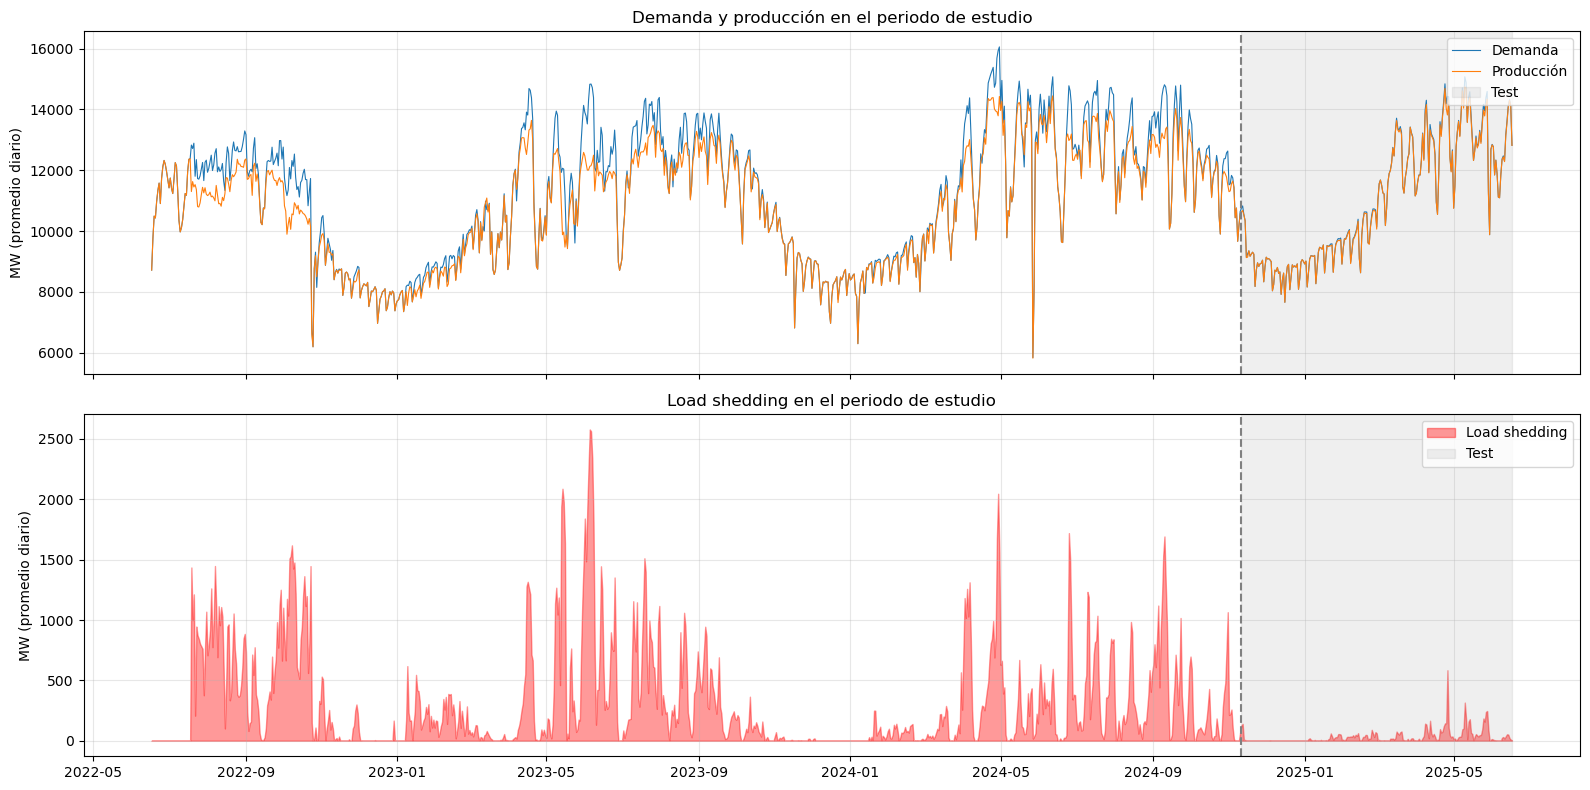

In [6]:
# Contexto del periodo de estudio (promedios diarios). Solo se grafica la serie, no se usa para decidir.
daily = X.groupby(X["datetime"].dt.date)[["demand_mw", "generation_mw", TARGET]].mean()
daily.index = pd.to_datetime(daily.index)
split_date = test_set_x["datetime"].min()

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axes[0].plot(daily.index, daily["demand_mw"], linewidth=0.8, label="Demanda")
axes[0].plot(daily.index, daily["generation_mw"], linewidth=0.8, label="Producción")
axes[0].set_ylabel("MW (promedio diario)")
axes[0].set_title("Demanda y producción en el periodo de estudio")
axes[1].fill_between(daily.index, daily[TARGET], color="red", alpha=0.4, label="Load shedding")
axes[1].set_ylabel("MW (promedio diario)")
axes[1].set_title("Load shedding en el periodo de estudio")
for ax in axes:
    ax.axvspan(split_date, daily.index.max(), color="gray", alpha=0.12, label="Test")
    ax.axvline(split_date, color="gray", linestyle="--")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observaciones
- **Train:** 21,828 registros (2022-06-17 → 2024-11-10). **Test:** 5,457 registros (2024-11-10 → 2025-06-17).
- La gráfica muestra un **cambio de régimen** en Test: el load shedding de 2025 es mucho menor que en las mismas temporadas de 2023 y 2024. Esto afectará la comparación entre CV y Test.

### 5. Análisis Exploratorio de Datos (solo Train)
Se presentan los elementos necesarios para justificar el preprocesamiento: faltantes, escalas, variables categóricas, distribución del objetivo y variables relevantes.

#### 5.1 Valores faltantes y escalas en Train

In [7]:
train_missing = train_set_x.isnull().mean().mul(100).round(1)
print("% de faltantes en Train")
print(train_missing[train_missing > 0].sort_values(ascending=False).to_string())
print(border)
print("Escala de las variables numéricas en Train")
print(train_set_x.describe().T[["mean", "std", "min", "max"]].round(1).to_string())

% de faltantes en Train
nepal          100.0
remarks         92.2
india_adani     91.4
wind            39.7
----------------------------------------
Escala de las variables numéricas en Train
                                               mean          std                  min                  max
datetime              2023-08-30 10:43:43.639362304          NaN  2022-06-17 13:00:00  2024-11-10 18:00:00
generation_mw                          10860.575224  2078.284156               1026.0              16477.0
demand_mw                              11182.725261  2351.546675                921.0              17200.0
gas                                     5309.937924   871.045074                 49.0               8448.0
liquid_fuel                             1883.645043  1239.222582                  0.0               8179.0
coal                                    2441.663735  1175.234497                  0.0               7079.0
hydro                                      99.73928    69.9

### Observaciones
- **Faltantes en Train:** `nepal` (100%), `remarks` (92.2%), `india_adani` (91.4%) y `wind` (39.7%). Las dos primeras fuentes no aportan información en Train y se descartan; `remarks` faltante significa "no es hora pico", por lo que se imputa con una categoría propia.
- **Escalas muy distintas:** `generation_mw` y `demand_mw`,`india_tripura` en decenas de MW y el clima en °C o %. Sin escalamiento, la distancia ‖x − x'‖ del kernel RBF quedaría dominada por las variables en MW.
- **Mínimos sospechosos:** `demand_mw` = 921 y `generation_mw` = 1,026 MW, muy por debajo del nivel normal de la red. No se eliminan, para mantener la comparabilidad con la práctica anterior; su efecto se analiza en la sección 16.1.

#### 5.2 Distribución de la variable objetivo

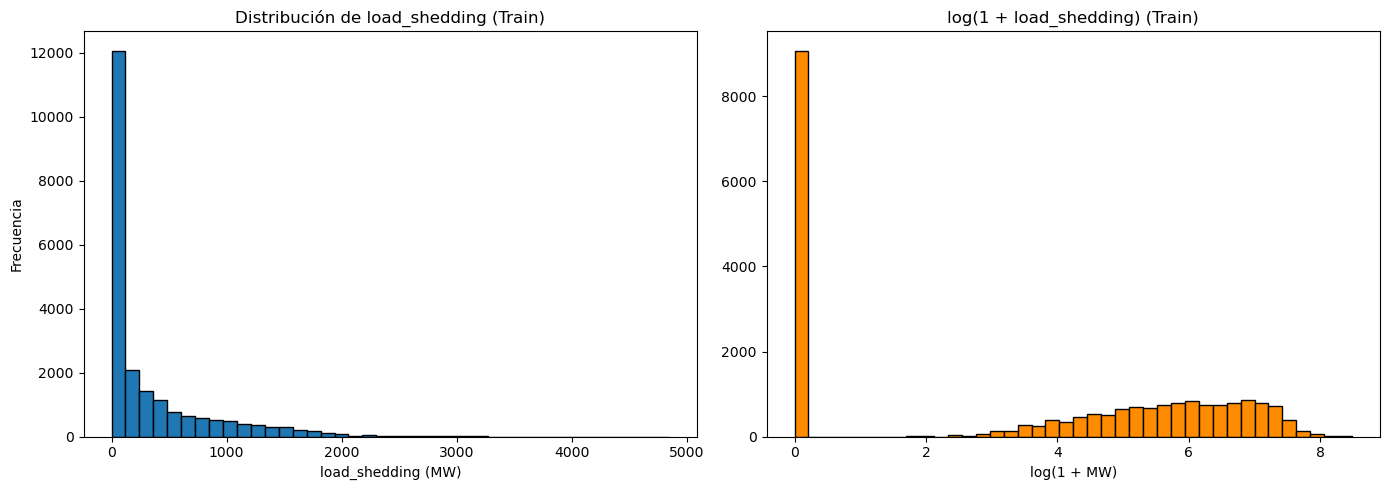

Horas con load_shedding = 0: 41.6%
count    21828.0
mean       320.6
std        496.0
min          0.0
25%          0.0
50%         75.0
75%        441.0
max       4847.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(train_set_y, bins=40, edgecolor="black")
axes[0].set_title("Distribución de load_shedding (Train)")
axes[0].set_xlabel("load_shedding (MW)")
axes[0].set_ylabel("Frecuencia")
axes[1].hist(np.log1p(train_set_y), bins=40, edgecolor="black", color="darkorange")
axes[1].set_title("log(1 + load_shedding) (Train)")
axes[1].set_xlabel("log(1 + MW)")
plt.tight_layout()
plt.show()

print(f"Horas con load_shedding = 0: {(train_set_y == 0).mean():.1%}")
print(train_set_y.describe().round(1).to_string())

### Observaciones
- **Muchos ceros y fuerte asimetría:** el 41.6% de las horas tiene `load_shedding = 0`, la mediana es 75 MW, la media 320.6 MW y el máximo 4,847 MW.
- Los valores altos se concentran en verano y son eventos reales, no errores aislados.
- **Implicaciones para SVR:**
  - El RMSE estará dominado por los picos y el MAE representa mejor el error típico.
  - Un modelo continuo no produce ceros exactos, así que habrá predicciones ligeramente negativas o positivas cuando el valor real es 0.

#### 5.3 Relación con hora, mes y demanda

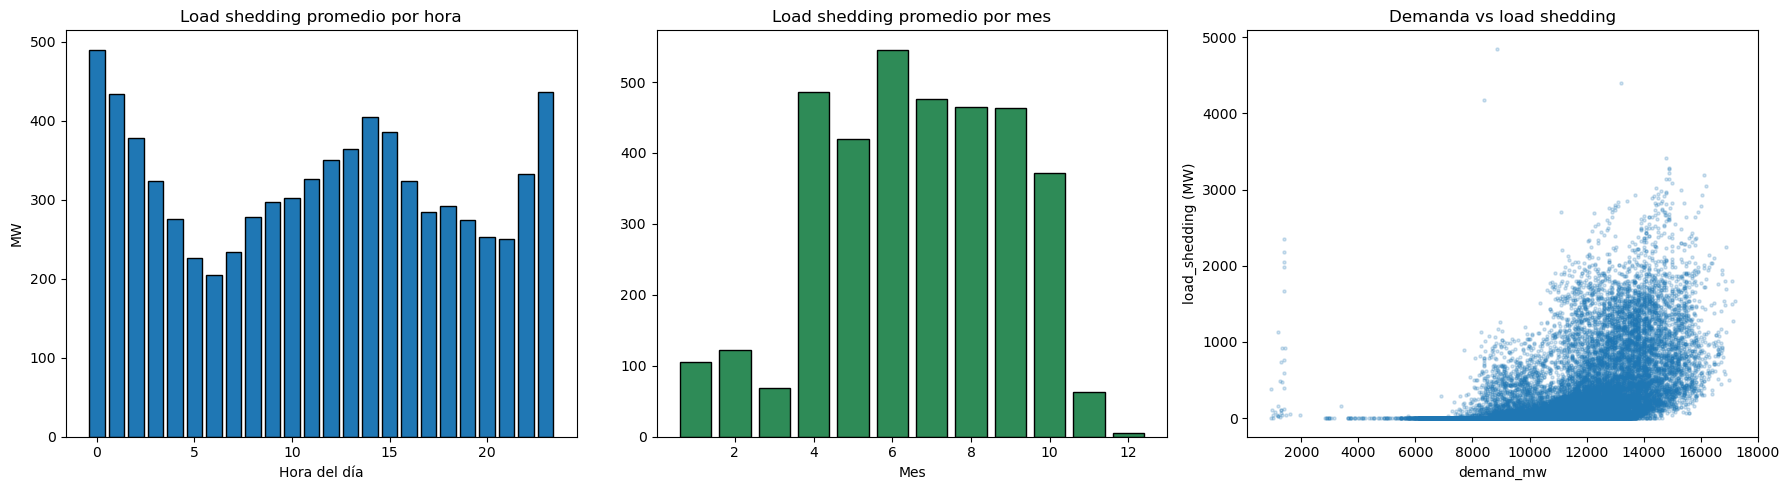

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

hourly_mean = train_set_y.groupby(train_set_x["datetime"].dt.hour).mean()
axes[0].bar(hourly_mean.index, hourly_mean.values, edgecolor="black")
axes[0].set_title("Load shedding promedio por hora")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("MW")

monthly_mean = train_set_y.groupby(train_set_x["datetime"].dt.month).mean()
axes[1].bar(monthly_mean.index, monthly_mean.values, edgecolor="black", color="seagreen")
axes[1].set_title("Load shedding promedio por mes")
axes[1].set_xlabel("Mes")

axes[2].scatter(train_set_x["demand_mw"], train_set_y, alpha=0.2, s=5)
axes[2].set_title("Demanda vs load shedding")
axes[2].set_xlabel("demand_mw")
axes[2].set_ylabel("load_shedding (MW)")

plt.tight_layout()
plt.show()

### Observaciones
- **Hora:** relación no lineal y periódica. El pico principal es alrededor de medianoche (~490 MW), hay uno secundario a las 14:00–15:00 y el mínimo está a las 06:00 (~204 MW). Las 23:00 y las 00:00 son contiguas, por lo que la hora se codifica con *one-hot* y no como número.
- **Mes:** estacionalidad marcada. De abril a septiembre el promedio supera los 400 MW (máximo en junio); en diciembre es casi nulo. Se codifica con *one-hot*.
- **Demanda:** forma de codo. El load shedding es casi nulo hasta ~10,000 MW y luego crece rápidamente. Esta relación no lineal es la motivación para los kernels polinomial y RBF.

#### 5.4 Feature Engineering
Se reutilizan las características de la práctica anterior:
- **Temporales:** `Hour`, `Hour_sin`, `Hour_cos`, `DayOfWeek`, `IsWeekend` (viernes y sábado en Bangladesh), `Month`, `DayOfYear`.
- **Clima promedio nacional (Open-Meteo, 8 capitales de división):** `temperature_2m`, `relative_humidity_2m`, `apparent_temperature`, `precipitation`, `cloud_cover`.

Ninguna usa información de `y`, y todas se pueden calcular para una hora futura (fecha + pronóstico del clima). Las mismas funciones se aplican a Train y Test.

In [10]:
def add_time_features(df):
    df = df.copy()
    df["Hour"] = df["datetime"].dt.hour
    df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24.0)
    df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24.0)
    df["DayOfWeek"] = df["datetime"].dt.dayofweek
    df["Month"] = df["datetime"].dt.month
    df["DayOfYear"] = df["datetime"].dt.dayofyear
    # En Bangladesh el fin de semana es viernes y sábado
    df["IsWeekend"] = df["DayOfWeek"].isin([4, 5]).astype(int)
    return df


weather_path = "bangladesh_weather_hourly.csv"
weather_vars = ["temperature_2m", "relative_humidity_2m", "apparent_temperature", "precipitation", "cloud_cover"]
cities = {
    "Dhaka": (23.8103, 90.4125), "Chattogram": (22.3569, 91.7832),
    "Khulna": (22.8456, 89.5403), "Rajshahi": (24.3745, 88.6042),
    "Sylhet": (24.8949, 91.8687), "Barishal": (22.7010, 90.3535),
    "Rangpur": (25.7439, 89.2752), "Mymensingh": (24.7471, 90.4203),
}


def download_weather(start_date, end_date):
    import requests

    params = {
        "latitude": ",".join(str(lat) for lat, _ in cities.values()),
        "longitude": ",".join(str(lon) for _, lon in cities.values()),
        "start_date": start_date, "end_date": end_date,
        "hourly": ",".join(weather_vars),
        "timezone": "Asia/Dhaka",
    }
    response = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
    response.raise_for_status()
    frames = []
    for city, location in zip(cities, response.json()):
        df = pd.DataFrame(location["hourly"])
        df["city"] = city
        frames.append(df)
    per_city = pd.concat(frames)
    per_city["time"] = pd.to_datetime(per_city["time"])
    # Promedio nacional: media simple de las 8 ciudades en cada hora
    return per_city.groupby("time")[weather_vars].mean()


first_hour = X["datetime"].min().floor("h")
last_hour = X["datetime"].max().floor("h")
weather = None
if os.path.exists(weather_path):
    weather = pd.read_csv(weather_path, parse_dates=["time"], index_col="time")
    if weather.index.min() > first_hour or weather.index.max() < last_hour:
        weather = None
if weather is None:
    weather = download_weather(str(first_hour.date()), str(last_hour.date()))
    weather.to_csv(weather_path)


def add_weather_features(df, weather):
    df = df.copy()
    hourly_weather = weather.reindex(df["datetime"].dt.floor("h"))
    for var in weather_vars:
        df[var] = hourly_weather[var].to_numpy()
    return df


train_set_x = add_weather_features(add_time_features(train_set_x), weather)
test_set_x = add_weather_features(add_time_features(test_set_x), weather)
print("Predictores:", train_set_x.columns.tolist())

Predictores: ['datetime', 'generation_mw', 'demand_mw', 'gas', 'liquid_fuel', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'india_tripura', 'india_adani', 'nepal', 'remarks', 'Hour', 'Hour_sin', 'Hour_cos', 'DayOfWeek', 'Month', 'DayOfYear', 'IsWeekend', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'cloud_cover']


#### 5.5 Correlaciones con el objetivo (Train)

In [11]:
corr_with_target = pd.concat(
    [train_set_x.select_dtypes(include=np.number), train_set_y], axis=1
).corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr_with_target.round(3)

demand_mw               0.542
apparent_temperature    0.393
liquid_fuel             0.372
generation_mw           0.368
temperature_2m          0.365
india_tripura           0.311
gas                     0.242
india_adani             0.239
india_bheramara_hvdc    0.200
cloud_cover             0.169
IsWeekend              -0.118
DayOfWeek              -0.065
hydro                   0.057
solar                   0.032
coal                    0.029
Hour_sin               -0.025
Hour_cos                0.023
Hour                   -0.020
Month                   0.017
DayOfYear               0.014
relative_humidity_2m   -0.014
wind                   -0.007
precipitation           0.007
nepal                     NaN
Name: load_shedding, dtype: float64

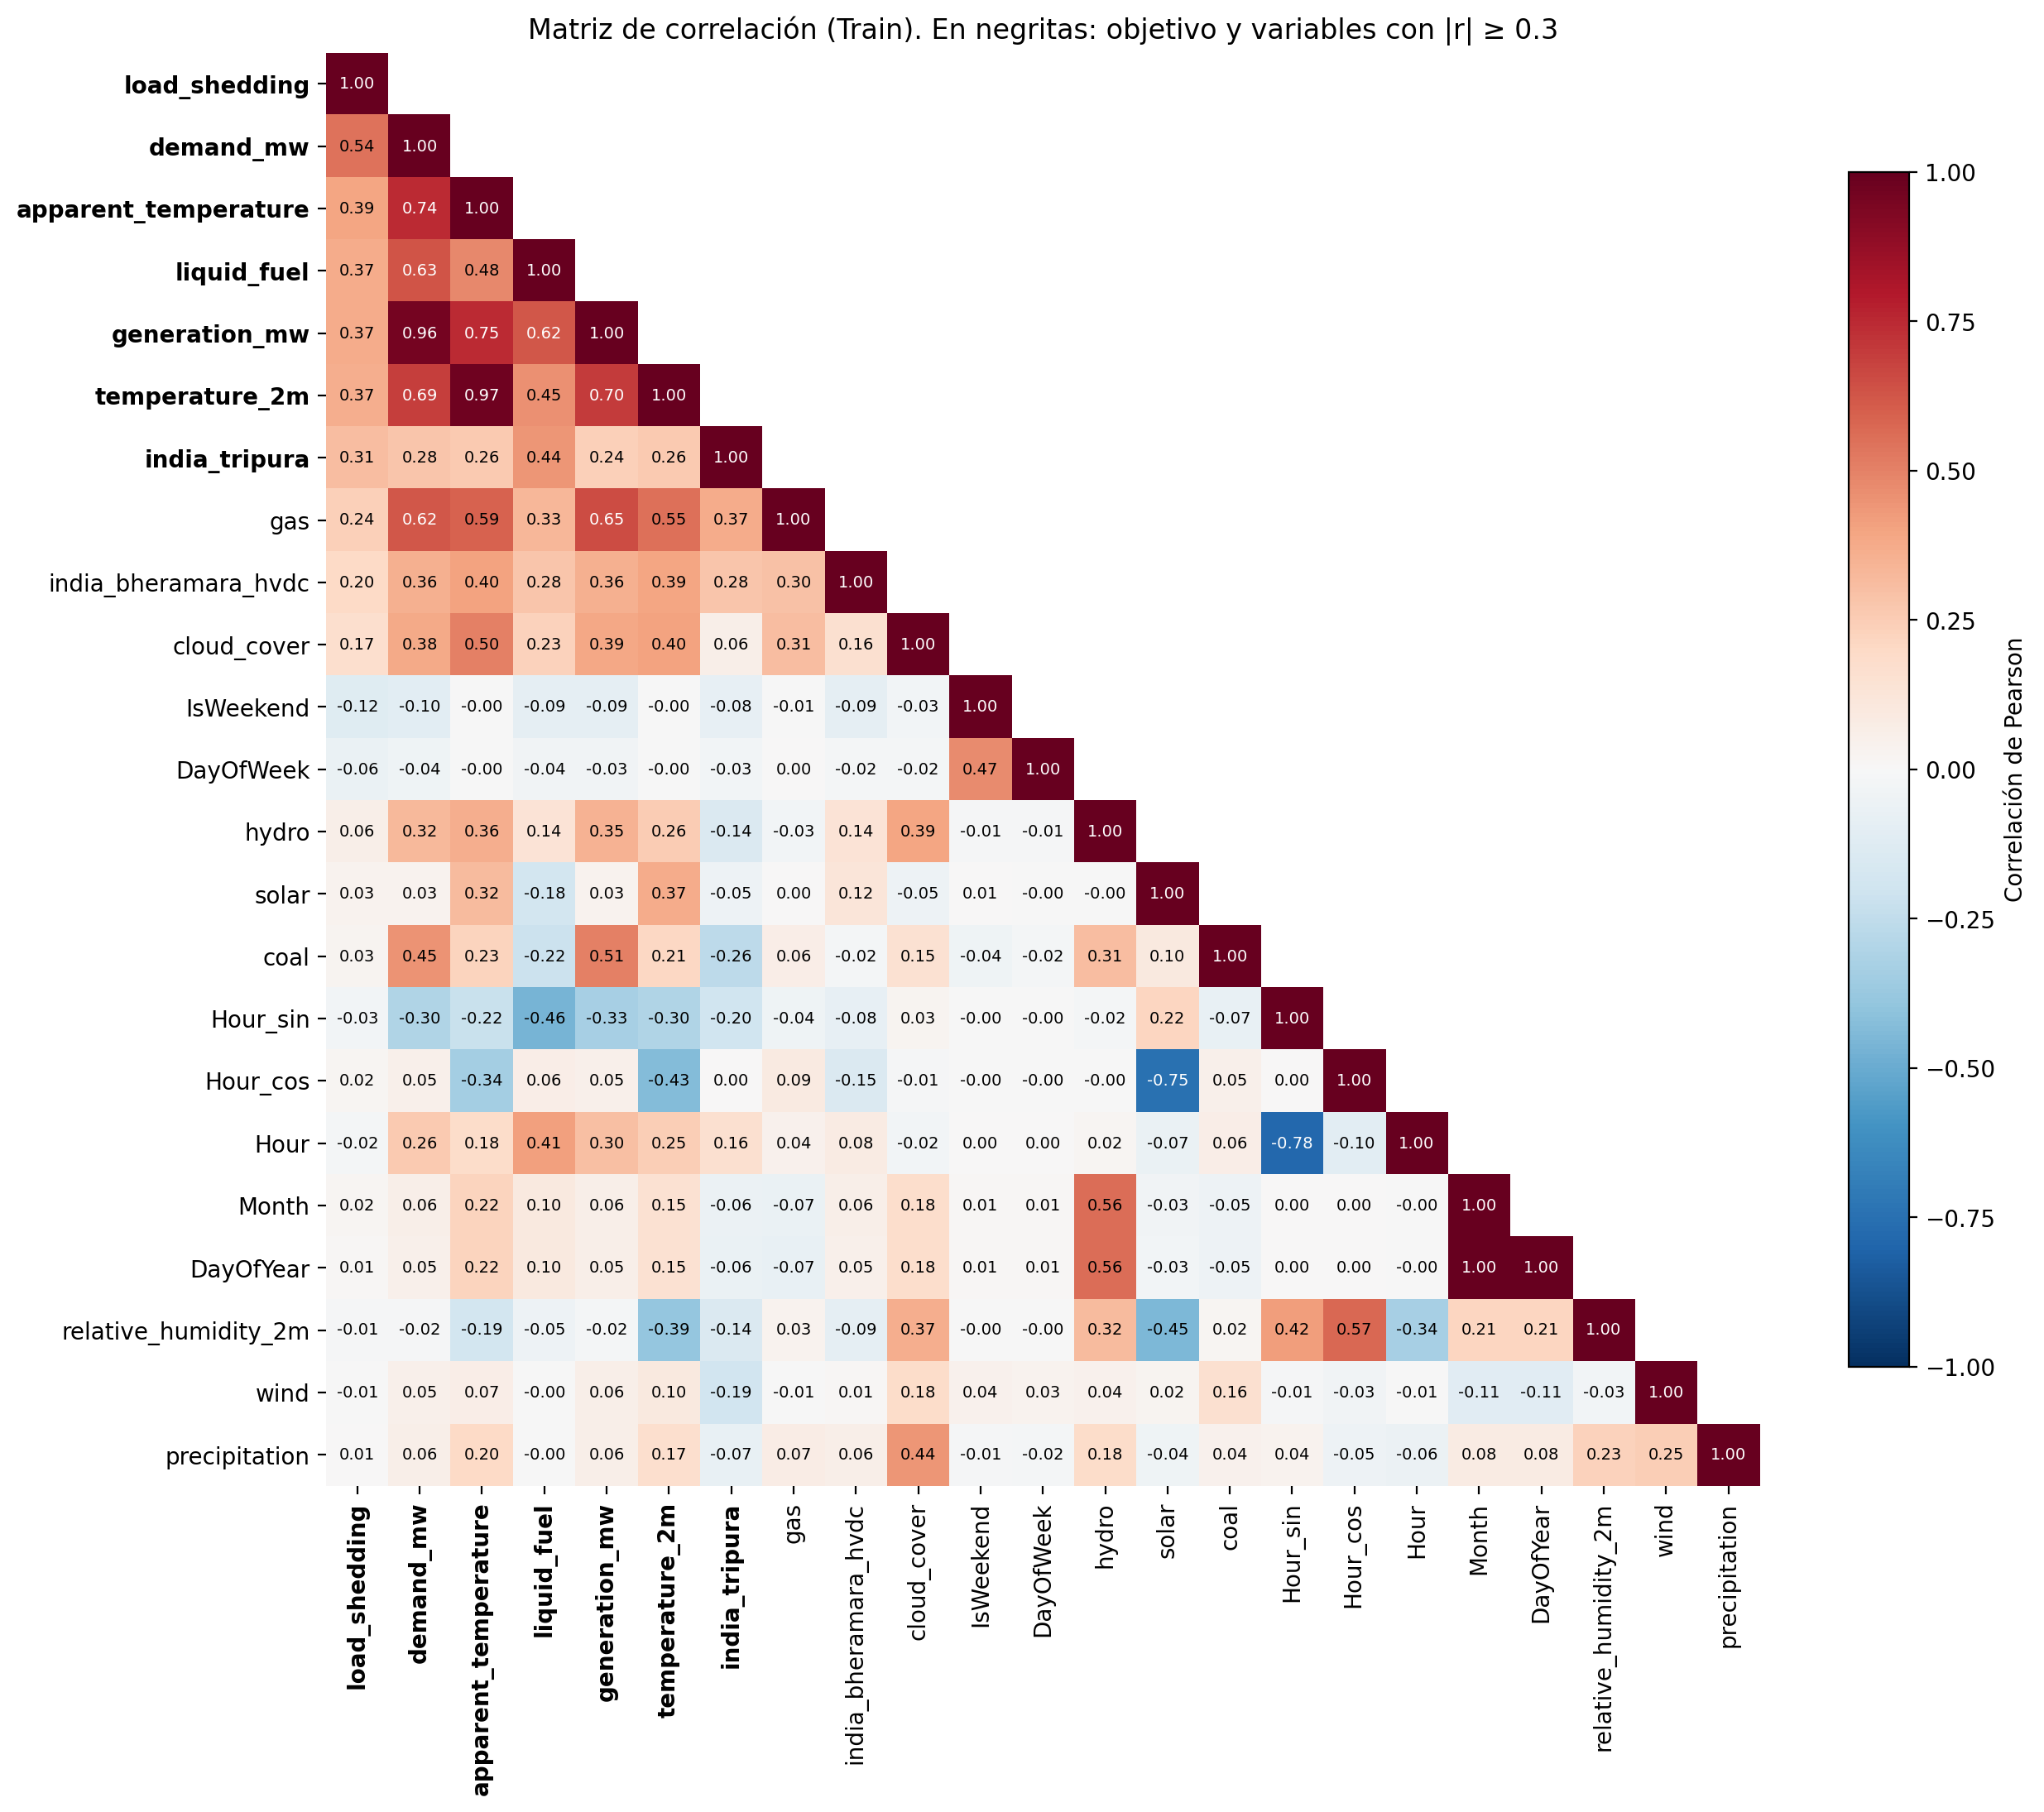

In [ ]:
# Mapa de calor de correlación de Pearson entre las variables numéricas y el objetivo (solo Train).
# Se excluyen las variables con menos del 50% de datos en Train (india_adani, nepal), igual que en el Pipeline.
heatmap_data = pd.concat([train_set_x.select_dtypes(include=np.number), train_set_y], axis=1)
heatmap_data = heatmap_data.loc[:, heatmap_data.notna().mean() >= 0.5]
corr_matrix = heatmap_data.corr()
order = [TARGET] + corr_matrix[TARGET].drop(TARGET).abs().sort_values(ascending=False).index.tolist()
corr_matrix = corr_matrix.loc[order, order]
selected = corr_matrix[TARGET].drop(TARGET).abs().ge(0.3)

fig, ax = plt.subplots(figsize=(13, 11))
masked = np.ma.masked_where(np.triu(np.ones_like(corr_matrix, dtype=bool), k=1), corr_matrix.to_numpy())
im = ax.imshow(masked, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(order)):
    for j in range(i + 1):
        value = corr_matrix.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(value) > 0.6 else "black")
ax.set_xticks(range(len(order)))
ax.set_yticks(range(len(order)))
ax.set_xticklabels(order, rotation=90)
ax.set_yticklabels(order)
# En negritas: el objetivo y las variables que pasan el filtro |r| >= 0.3
for labels in (ax.get_xticklabels(), ax.get_yticklabels()):
    for label in labels:
        if label.get_text() == TARGET or selected.get(label.get_text(), False):
            label.set_fontweight("bold")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlación de Pearson")
ax.set_title("Matriz de correlación (Train). En negritas: objetivo y variables con |r| ≥ 0.3")
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/correlaciones.png", dpi=200, bbox_inches="tight")
plt.show()

### Observaciones (mapa de calor)
- **Objetivo:** solo 6 variables superan |r| ≥ 0.3 con `load_shedding` (en negritas): `demand_mw` (0.54), `apparent_temperature` (0.39), `liquid_fuel` (0.37), `generation_mw` (0.37), `temperature_2m` (0.37) e `india_tripura` (0.31).
- **Multicolinealidad fuerte entre predictores:** `demand_mw`–`generation_mw` (0.96) y `temperature_2m`–`apparent_temperature` (0.97). Las dos parejas pasan el filtro, así que los modelos lineales reciben información casi duplicada; esto justifica la penalización L2 de Ridge.
- **Demanda y clima están ligados:** `demand_mw` correlaciona 0.74 con la sensación térmica y 0.69 con la temperatura (más calor, más demanda por aire acondicionado). Parte del efecto del clima sobre el objetivo pasa por la demanda.
- **Variables redundantes por construcción:** `Month`–`DayOfYear` (1.00), `DayOfWeek`–`IsWeekend` (0.47) y `Hour`–`Hour_sin` (−0.78). Ninguna pasa el filtro; la hora y el mes entran como *one-hot*.
- **Limitación:** Pearson mide solo relaciones lineales. El objetivo depende del déficit `demand_mw − generation_mw`, que no aparece como variable propia: dos variables con r = 0.96 entre sí contienen esa diferencia, pero solo un modelo no lineal o con interacciones (polinomial, SVR RBF, árboles) puede aprovecharla.

### Observaciones
- **Mayores correlaciones:** `demand_mw` (0.542), `apparent_temperature` (0.393), `liquid_fuel` (0.372), `generation_mw` (0.368), `temperature_2m` (0.365) e `india_tripura` (0.311).
- Las variables temporales numéricas (`Hour_sin`, `Month`, `DayOfYear`) tienen correlación casi nula porque su relación es no monótona, no porque sean irrelevantes. La hora y el mes entran al modelo como *one-hot*.
- **Limitación:** Pearson solo mide relaciones lineales. El filtro |r| ≥ 0.3 se mantiene para comparar con la práctica anterior con las mismas variables, pero podría descartar variables útiles para un kernel no lineal.

#### Conclusión del EDA: decisiones de preprocesamiento
- **Faltantes:** imputación con la **mediana** (robusta ante la asimetría) para las numéricas; `remarks` se imputa con la categoría constante `"None"` (la ausencia significa "no es hora pico"). `india_adani` y `nepal` se descartan por cubrir menos del 50% de Train.
- **Escalamiento:** `StandardScaler` dentro del Pipeline. Es obligatorio para SVR: los kernels RBF y polinomial dependen de distancias/productos punto, y variables en miles de MW dominarían a las de grados °C.
- **Codificación:** *one-hot* para `remarks` (nominal), `Hour` y `Month` (relación no monótona y cíclica con el objetivo).
- **Selección de variables:** se mantiene el filtro de la práctica anterior (|r| ≥ 0.3 con el objetivo en Train) para comparar SVR con Ridge y XGBoost sobre las mismas variables.
- **Transformación del objetivo:** `y` se estandariza con `TransformedTargetRegressor`. En SVR, `epsilon` (ancho del tubo sin penalización, por defecto 0.1) y `C` están en las unidades de `y`; con `y` en MW (desviación ≈ 500 MW) un `epsilon` de 0.1 MW y `C = 1` carecen de sentido. Al estandarizar, `epsilon = 0.1` equivale a 0.1 desviaciones estándar y los valores por defecto vuelven a ser razonables. Las métricas se reportan siempre en MW.

## Fase 3. Pipeline de preprocesamiento

### 6. Construcción del Pipeline
Estructura: `TransformedTargetRegressor( Pipeline = Preprocesamiento + SVR )`. Imputación, escalamiento, codificación y escalamiento de `y` se ajustan **solo** con la parte de entrenamiento de cada fold.

In [12]:
train_coverage = train_set_x.select_dtypes(include=np.number).notna().mean()
sparse_features = train_coverage[train_coverage < 0.5].index.tolist()
print("Variables descartadas por falta de datos en Train:", sparse_features)

categorical_features = ["remarks"]
onehot_features = ["Hour", "Month"]
numeric_features = [
    col for col in train_set_x.columns
    if col not in ["datetime"] + categorical_features + onehot_features + sparse_features
]

corr_threshold = 0.3
train_corr = pd.concat([train_set_x[numeric_features], train_set_y], axis=1).corr()[TARGET].drop(TARGET)
weak_features = train_corr[train_corr.abs() < corr_threshold].index.tolist()
numeric_features = [col for col in numeric_features if col not in weak_features]
print("Variables descartadas por correlación débil:", weak_features)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
    ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_features),
])

print("Numéricas (escaladas):", numeric_features)
print("Categóricas (one-hot):", categorical_features + onehot_features)


def make_svr(**svr_params):
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessing", preprocessor),
            ("model", SVR(cache_size=1000, **svr_params)),
        ]),
        transformer=StandardScaler(),
    )


make_svr(kernel="rbf")

Variables descartadas por falta de datos en Train: ['india_adani', 'nepal']
Variables descartadas por correlación débil: ['gas', 'coal', 'hydro', 'solar', 'wind', 'india_bheramara_hvdc', 'Hour_sin', 'Hour_cos', 'DayOfWeek', 'DayOfYear', 'IsWeekend', 'relative_humidity_2m', 'precipitation', 'cloud_cover']
Numéricas (escaladas): ['generation_mw', 'demand_mw', 'liquid_fuel', 'india_tripura', 'temperature_2m', 'apparent_temperature']
Categóricas (one-hot): ['remarks', 'Hour', 'Month']


,regressor,Pipeline(step..._size=1000))])
,transformer,StandardScaler()
,func,None
,inverse_func,None
,check_inverse,True
,transformers,"[('num', ...), ('cat', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


### Validación cruzada temporal (5 folds)
Se usa `TimeSeriesSplit(n_splits=5, gap=24)`, la misma estrategia de la práctica anterior: ventana creciente, cada fold se entrena solo con horas anteriores y valida con el bloque siguiente; el `gap` de 24 registros evita que la autocorrelación entre horas contiguas infle el desempeño. Un `KFold` aleatorio usaría el futuro para predecir el pasado.

In [3]:
cv_folds = list(TimeSeriesSplit(n_splits=5, gap=24).split(train_set_x))
for fold, (train_idx, val_idx) in enumerate(cv_folds, start=1):
    print(
        f"Fold {fold}: train {train_set_x['datetime'].iloc[train_idx[0]]:%Y-%m-%d} → "
        f"{train_set_x['datetime'].iloc[train_idx[-1]]:%Y-%m-%d} ({len(train_idx):>5}) | "
        f"val {train_set_x['datetime'].iloc[val_idx[0]]:%Y-%m-%d} → "
        f"{train_set_x['datetime'].iloc[val_idx[-1]]:%Y-%m-%d} ({len(val_idx)})"
    )

scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}
cv_results = {}


def evaluate_cv(name, model):
    start = time.time()
    scores = cross_validate(
        model, train_set_x, train_set_y, cv=cv_folds, scoring=scoring,
        return_train_score=True, n_jobs=-1,
    )
    cv_results[name] = scores
    print(f"{name}  ({time.time() - start:.1f} s)")
    print(f"  RMSE: {-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}"
          f"   (Train: {-scores['train_rmse'].mean():.2f})")
    print(f"  MAE:  {-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}")
    print(f"  R2:   {scores['test_r2'].mean():.3f} ± {scores['test_r2'].std():.3f}")
    print("  RMSE por fold:", np.round(-scores["test_rmse"], 1))

NameError: name 'TimeSeriesSplit' is not defined

### Pipeline para los modelos de árboles
Los árboles no necesitan escalamiento (cada división depende solo del orden de los valores), pero se usa el mismo `preprocessor` que en el SVR: así todos los modelos reciben exactamente las mismas variables y la comparación es directa. El `StandardScaler` no cambia el orden de los valores, por lo que no afecta a los árboles.

Tampoco se escala `y`: los árboles predicen promedios de hojas en MW y la pérdida cuadrática no depende de la escala.

In [1]:
def make_tree_model(estimator):
    return Pipeline([("preprocessing", preprocessor), ("model", estimator)])


def grid_table(grid):
    results = pd.DataFrame(grid.cv_results_)
    params = [c for c in results.columns if c.startswith("param_")]
    table = results[params].rename(columns=lambda c: c.split("__")[-1]).assign(
        RMSE_val=-results["mean_test_score"],
        RMSE_std=results["std_test_score"],
        RMSE_train=-results["mean_train_score"],
        fit_time=results["mean_fit_time"],
    )
    return table.sort_values("RMSE_val").round(2)


# IV. Experimentación

## Fase 4a. Modelos lineales

### 7.1 Referencia y modelos lineales
- `DummyRegressor`: predice la media de Train de cada fold. Es el mínimo que cualquier modelo útil debe superar.
- `LinearRegression`: mínimos cuadrados ordinarios, $\min_\beta \lVert y - X\beta \rVert^2$.
- `Ridge` (α = 1): añade la penalización L2 $\alpha \lVert \beta \rVert^2$, que reduce los coeficientes y mitiga la multicolinealidad (por ejemplo, entre `demand_mw` y `generation_mw`).

Se usa el mismo `preprocessor` que en el resto de la práctica. `y` no se escala: en mínimos cuadrados la solución no depende de la escala del objetivo.


In [2]:
def make_linear(estimator):
    return Pipeline([("preprocessing", preprocessor), ("model", estimator)])


evaluate_cv("Dummy (media)", make_linear(DummyRegressor()))
evaluate_cv("Linear Regression", make_linear(LinearRegression()))
evaluate_cv("Ridge (alpha=1)", make_linear(Ridge(alpha=1)))


NameError: name 'evaluate_cv' is not defined

### 7.2 Regresión polinomial
La regresión polinomial sigue siendo un modelo **lineal en los parámetros**: se amplía $X$ con potencias e interacciones de las variables y se ajusta un Ridge sobre las nuevas columnas.

- `PolynomialFeatures` se aplica **solo a las 6 variables numéricas escaladas**. Las columnas *one-hot* (hora, mes, `remarks`) ya son indicadoras: elevarlas al cuadrado no cambia nada y sus interacciones multiplicarían el número de columnas.
- Con grado 2 las 6 numéricas pasan a 27 columnas (lineales, cuadrados e interacciones como `demand_mw × generation_mw`); con grado 3, a 83.
- Se usa `Ridge` en lugar de `LinearRegression` porque los términos polinomiales están muy correlacionados entre sí.


In [ ]:
def make_poly(degree=2, alpha=1.0):
    poly_preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ]), numeric_features),
        ("cat", categorical_pipeline, categorical_features),
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_features),
    ])
    return Pipeline([("preprocessing", poly_preprocessor), ("model", Ridge(alpha=alpha))])


evaluate_cv("Polinomial grado 2 (alpha=1)", make_poly(degree=2, alpha=1))


### 7.3 Optimización de los modelos lineales
- **Ridge:** misma rejilla de α que en `BangladeshEnergyPowerGrid.ipynb`, ampliada con 1000 y 10000 para comprobar que el óptimo no está en el límite.
- **Polinomial:** grado (2, 3) junto con α, porque un grado mayor necesita más regularización.


In [ ]:
start = time.time()
ridge_grid = GridSearchCV(
    estimator=make_linear(Ridge()),
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]},
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    return_train_score=True,
    refit=True,
    n_jobs=-1,
)
ridge_grid.fit(train_set_x, train_set_y)
best_ridge = ridge_grid.best_estimator_
ridge_name = f"Ridge (alpha={ridge_grid.best_params_['model__alpha']})"
print(f"Ridge: {ridge_grid.best_params_}  ({time.time() - start:.0f} s)")
display(grid_table(ridge_grid))

start = time.time()
poly_grid = GridSearchCV(
    estimator=make_poly(),
    param_grid={
        "preprocessing__num__poly__degree": [2, 3],
        "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
    },
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    return_train_score=True,
    refit=True,
    n_jobs=-1,
)
poly_grid.fit(train_set_x, train_set_y)
best_poly = poly_grid.best_estimator_
poly_name = (f"Polinomial grado {poly_grid.best_params_['preprocessing__num__poly__degree']} "
             f"(alpha={poly_grid.best_params_['model__alpha']})")
print(f"Polinomial: {poly_grid.best_params_}  ({time.time() - start:.0f} s)")
display(grid_table(poly_grid))

evaluate_cv(ridge_name, best_ridge)
evaluate_cv(poly_name, best_poly)


In [ ]:
# ¿Por qué el polinomio de grado 2 mejora tanto a la recta? Relación del objetivo con el déficit demanda − generación (Train)
deficit = train_set_x["demand_mw"] - train_set_x["generation_mw"]
print(f"Corr(load_shedding, demanda − generación): {np.corrcoef(deficit.fillna(0), train_set_y)[0, 1]:.3f}")
print(f"Horas con |load_shedding − déficit| < 5 MW: {(abs(train_set_y - deficit) < 5).mean():.1%}")
print(f"Horas con load_shedding = 0 y déficit ≤ 0:  {((train_set_y == 0) & (deficit <= 0)).mean():.1%}")
print(f"Rango del déficit en Train: {deficit.min():,.0f} → {deficit.max():,.0f} MW")

poly_coef = pd.Series(
    best_poly.named_steps["model"].coef_,
    index=best_poly.named_steps["preprocessing"].get_feature_names_out(),
)
print(border)
print("Coeficientes de mayor magnitud (MW por desviación estándar)")
poly_coef.reindex(poly_coef.abs().sort_values(ascending=False).index).head(10).round(1)


### Observaciones (modelos lineales)
_Pendiente de ejecutar._


## Fase 4b. Support Vector Regression

### 7.4 Kernels con parámetros por defecto
`make_svr` envuelve el Pipeline en un `TransformedTargetRegressor` que estandariza `y` (ver la conclusión del EDA). Parámetros por defecto: `C = 1`, `epsilon = 0.1`.
- **Lineal:** `SVR(kernel="linear")`. La misma familia de funciones que `LinearRegression`, pero con la pérdida ε-insensible, que crece de forma lineal y no cuadrática.
- **Polinomial:** `degree = 3`, `coef0 = 0`, `gamma = "scale"`.
- **RBF:** $K(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$, `gamma = "scale"`.


In [ ]:
evaluate_cv("SVR Lineal", make_svr(kernel="linear"))
evaluate_cv("SVR Polinomial", make_svr(kernel="poly"))
evaluate_cv("SVR RBF", make_svr(kernel="rbf"))


### 7.5 Optimización del SVR RBF
Misma rejilla que en `LoadSheddingSVR.ipynb`: `C` controla la penalización de los puntos fuera del tubo ε y `gamma` el alcance de cada vector de soporte. Se buscan juntos porque interactúan (un `gamma` pequeño, función suave, necesita un `C` grande).


In [ ]:
start = time.time()
rbf_grid = GridSearchCV(
    estimator=make_svr(kernel="rbf"),
    param_grid={
        "regressor__model__C": [0.01, 0.1, 1, 10, 100],
        "regressor__model__gamma": ["scale", 0.001, 0.01, 0.1, 1, 10],
    },
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    return_train_score=True,
    refit=True,
    n_jobs=-1,
)
rbf_grid.fit(train_set_x, train_set_y)
print(f"Tiempo de búsqueda: {time.time() - start:.0f} s")
best_svr = rbf_grid.best_estimator_
print("Mejores hiperparámetros:", rbf_grid.best_params_)
print(f"Mejor RMSE CV: {-rbf_grid.best_score_:.2f}")

rbf_results = pd.DataFrame(rbf_grid.cv_results_)
display((-rbf_results.pivot_table(
    index="param_regressor__model__C",
    columns=rbf_results["param_regressor__model__gamma"].astype(str),
    values="mean_test_score",
))[["scale", "0.001", "0.01", "0.1", "1", "10"]].round(1).rename_axis(index="C", columns="gamma"))

evaluate_cv("SVR RBF optimizado", best_svr)


### Observaciones (SVR)
_Pendiente de ejecutar._


## Fase 4c. Ensambles con parámetros por defecto

### 7.6 XGBoost
- **XGBoost** (`max_depth = 5`): modelo final de la práctica de regresión lineal, implementación optimizada de *gradient boosting*. Se usa como referencia para los ensambles de scikit-learn.


In [15]:
xgb_model = make_tree_model(XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8,
    colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1,
))

evaluate_cv("XGBoost (max_depth=5)", xgb_model)


Dummy (media)  (4.4 s)
  RMSE: 489.89 ± 129.51   (Train: 534.55)
  MAE:  392.12 ± 75.13
  R2:   -1.234 ± 1.671
  RMSE por fold: [475.1 740.2 379.5 405.5 449.1]


SVR RBF optimizado  (5.8 s)
  RMSE: 113.42 ± 43.30   (Train: 90.03)
  MAE:  46.25 ± 23.36
  R2:   0.827 ± 0.196
  RMSE por fold: [152.1 127.1  75.7 161.6  50.6]


XGBoost (max_depth=5)  (2.7 s)
  RMSE: 168.94 ± 67.21   (Train: 55.57)
  MAE:  95.20 ± 37.78
  R2:   0.702 ± 0.263
  RMSE por fold: [182.  285.9 137.5 157.6  81.7]


### 8. AdaBoost
`AdaBoostRegressor` (AdaBoost.R2, Drucker 1997) entrena árboles de forma secuencial. Después de cada árbol aumenta el peso de las muestras con mayor error relativo, de modo que el siguiente árbol se concentra en ellas. La predicción final es la **mediana ponderada** de los árboles, con más peso para los árboles más precisos.

Configuración por defecto: 50 árboles, `learning_rate = 1`, `loss = "linear"`. Se usa como base un árbol de `max_depth = 3` (el valor por defecto de scikit-learn para regresión).

In [16]:
evaluate_cv("AdaBoost", make_tree_model(AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3), random_state=RANDOM_STATE,
)))

AdaBoost  (2.8 s)
  RMSE: 469.79 ± 99.89   (Train: 464.26)
  MAE:  397.26 ± 106.29
  R2:   -0.970 ± 1.295
  RMSE por fold: [272.8 548.9 498.4 509.9 518.9]


### Observaciones
- **RMSE = 469.79 ± 99.89 MW, MAE = 397.26 MW, R² = −0.97.** Apenas mejora al Dummy (489.89 MW): con parámetros por defecto AdaBoost **no aprende** el problema.
- **No es sobreajuste:** el RMSE de Train (464 MW) es casi igual al de validación. Es un subajuste severo.
- **Por qué ocurre:**
  - AdaBoost.R2 asigna a cada árbol un peso según su error relativo al **peor** error de la muestra. Los registros con demanda o generación anómalas (< 5,000 MW, ver `LoadSheddingSVR.ipynb`, sección 16.1) producen errores enormes, reciben cada vez más peso y los árboles siguientes se concentran en ellos.
  - Con `learning_rate = 1` esa reponderación es agresiva, y con `max_depth = 3` cada árbol tiene pocas hojas para repartir entre los atípicos y el resto.
  - La predicción final es una mediana ponderada: si la mayoría de los árboles se especializa en atípicos, la mediana queda lejos de las horas normales.

### 9. Gradient Boosting
`GradientBoostingRegressor` construye el ensamble de forma aditiva: F_m(x) = F_{m−1}(x) + ν·h_m(x). Cada árbol h_m se ajusta a los residuos y − F_{m−1}(x) (el gradiente negativo de la pérdida cuadrática) y `learning_rate` (ν) reduce su contribución.

Configuración por defecto: 100 árboles, `learning_rate = 0.1`, `max_depth = 3`, `loss = "squared_error"`.

In [17]:
evaluate_cv("Gradient Boosting", make_tree_model(GradientBoostingRegressor(random_state=RANDOM_STATE)))

Gradient Boosting  (5.4 s)
  RMSE: 165.49 ± 54.94   (Train: 108.82)
  MAE:  94.92 ± 31.34
  R2:   0.707 ± 0.265
  RMSE por fold: [181.6 261.4 140.7 146.4  97.3]


### Observaciones
- **RMSE = 165.49 ± 54.94 MW, MAE = 94.92 MW, R² = 0.707.** Con parámetros por defecto queda al nivel de XGBoost (168.94 MW), que es la misma familia de modelos.
- Muy por encima de AdaBoost (−65% de RMSE). A diferencia de AdaBoost, Gradient Boosting no repondera las muestras: cada árbol corrige el residuo del ensamble con una contribución reducida (`learning_rate = 0.1`), así que un registro anómalo no domina el entrenamiento.
- **Brecha Train–validación moderada:** 108.8 frente a 165.5 MW.
- Sigue lejos del SVR RBF optimizado (113.42 MW): con 100 árboles de profundidad 3 el modelo aún tiene sesgo.

## Fase 5. Comparación inicial

### 10. Tabla comparativa (promedio ± desviación estándar entre los 5 folds)

In [18]:
def summarize(results):
    rows = []
    for name, s in results.items():
        rows.append({
            "Modelo": name,
            "RMSE": -s["test_rmse"].mean(), "RMSE std": s["test_rmse"].std(),
            "MAE": -s["test_mae"].mean(), "MAE std": s["test_mae"].std(),
            "R2": s["test_r2"].mean(), "R2 std": s["test_r2"].std(),
            "RMSE Train": -s["train_rmse"].mean(),
        })
    return pd.DataFrame(rows).set_index("Modelo").round(3)


summarize(cv_results)

,RMSE,RMSE std,MAE,MAE std,R2,R2 std,RMSE Train
Modelo,,,,,,,
Dummy (media),489.889,129.511,392.117,75.131,-1.234,1.671,534.546
SVR RBF optimizado,113.424,43.299,46.248,23.364,0.827,0.196,90.035
XGBoost (max_depth=5),168.943,67.209,95.203,37.782,0.702,0.263,55.574
AdaBoost,469.792,99.889,397.264,106.293,-0.970,1.295,464.264
Gradient Boosting,165.495,54.938,94.923,31.341,0.707,0.265,108.817


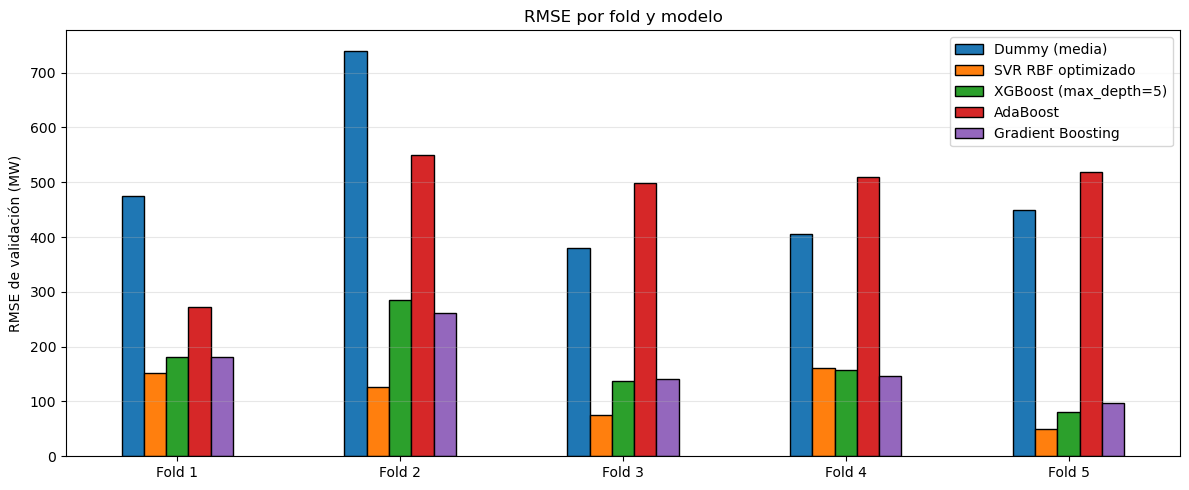

,Dummy (media),SVR RBF optimizado,XGBoost (max_depth=5),AdaBoost,Gradient Boosting
Fold 1,475.1,152.1,182.0,272.8,181.6
Fold 2,740.2,127.1,285.9,548.9,261.4
Fold 3,379.5,75.7,137.5,498.4,140.7
Fold 4,405.5,161.6,157.6,509.9,146.4
Fold 5,449.1,50.6,81.7,518.9,97.3


In [19]:
# Por legibilidad, el gráfico por fold muestra solo un modelo representativo de cada familia
fold_models = ["Dummy (media)", ridge_name, poly_name, "SVR Lineal", "SVR RBF optimizado",
               "XGBoost (max_depth=5)", "Gradient Boosting", "AdaBoost"]
fold_rmse = pd.DataFrame(
    {name: -cv_results[name]["test_rmse"] for name in fold_models},
    index=[f"Fold {i}" for i in range(1, 6)],
)

ax = fold_rmse.plot(kind="bar", figsize=(14, 5), edgecolor="black", rot=0)
ax.set_ylabel("RMSE de validación (MW)")
ax.set_title("RMSE por fold y modelo")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
fold_rmse.round(1)


### Observaciones
- **Ranking por defecto:** SVR RBF optimizado (113.4) < Gradient Boosting (165.5) ≈ XGBoost (168.9) < AdaBoost (469.8) ≈ Dummy (489.9).
- **Gradient Boosting** es más estable que XGBoost (desviación de 54.9 frente a 67.2 MW) y supera al SVR solo en el fold 4 (146.4 frente a 161.6 MW).
- **AdaBoost** es el único ensamble peor que el Dummy en algún fold (folds 3 a 5). Solo el fold 1, con pocas horas de entrenamiento y validación en invierno, le resulta favorable (272.8 MW).
- **El SVR optimizado es el mejor en 4 de 5 folds.** Para que la comparación sea justa, los dos ensambles se optimizan en la Fase 6, como se hizo con el SVR.

## Fase 6. Optimización de hiperparámetros

Se optimizan AdaBoost y Gradient Boosting con `GridSearchCV` sobre los mismos `cv_folds` y con RMSE como métrica, igual que el SVR.

### 11. AdaBoost
- `n_estimators`: número de árboles.
- `learning_rate`: reduce el peso de cada árbol; valores pequeños necesitan más árboles.
- `estimator__max_depth`: complejidad de cada árbol base.
- `loss`: cómo se convierte el error en pesos (`linear`, `square`).

In [20]:
start = time.time()
ada_grid = GridSearchCV(
    estimator=make_tree_model(AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=3), random_state=RANDOM_STATE,
    )),
    param_grid={
        "model__n_estimators": [50, 200],
        "model__learning_rate": [0.1, 1.0],
        "model__estimator__max_depth": [3, 6],
        "model__loss": ["linear", "square"],
    },
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    return_train_score=True,
    refit=True,
    n_jobs=-1,
)
ada_grid.fit(train_set_x, train_set_y)
print(f"Tiempo de búsqueda: {time.time() - start:.0f} s")

best_ada = ada_grid.best_estimator_
print("Mejores hiperparámetros:", ada_grid.best_params_)
print(f"Mejor RMSE CV: {-ada_grid.best_score_:.2f}")


grid_table(ada_grid).head(10)

Tiempo de búsqueda: 107 s
Mejores hiperparámetros: {'model__estimator__max_depth': 6, 'model__learning_rate': 0.1, 'model__loss': 'linear', 'model__n_estimators': 200}
Mejor RMSE CV: 203.58


,max_depth,learning_rate,loss,n_estimators,RMSE_val,RMSE_std,RMSE_train,fit_time
9,6,0.1,linear,200,203.58,41.65,143.92,19.93
8,6,0.1,linear,50,211.30,57.90,140.99,4.84
11,6,0.1,square,200,214.94,53.64,149.93,17.49
10,6,0.1,square,50,217.51,64.08,148.29,6.10
12,6,1.0,linear,50,225.98,35.24,165.48,3.93
15,6,1.0,square,200,230.63,37.99,169.91,10.73
13,6,1.0,linear,200,243.12,33.81,199.79,13.56
14,6,1.0,square,50,246.94,43.60,175.88,3.67
0,3,0.1,linear,50,346.05,111.39,344.41,2.16
2,3,0.1,square,50,368.52,121.28,371.59,2.39


### Observaciones
- **Mejor configuración:** `max_depth = 6`, `learning_rate = 0.1`, `loss = "linear"`, `n_estimators = 200`. RMSE CV de **203.58 ± 41.65 MW**, 57% menor que AdaBoost por defecto.
- **La profundidad del árbol base es lo más importante:** las 8 mejores combinaciones usan `max_depth = 6`. Con `max_depth = 3`, la mejor queda en 346 MW. Árboles más profundos separan mejor los registros anómalos en hojas propias, en vez de distorsionar todo el modelo.
- **`learning_rate = 0.1` es mejor que 1** en todas las combinaciones con `max_depth = 6`: reponderar de forma más suave reduce el efecto de los atípicos.
- **`loss = "linear"` supera a `"square"`** en 3 de las 4 combinaciones con `max_depth = 6`: la pérdida cuadrática amplifica aún más el peso de los errores grandes.
- **Sigue lejos del resto:** 203.6 MW frente a 165.5 MW del Gradient Boosting por defecto. El mecanismo de reponderación de AdaBoost es inadecuado para este problema, con muchos ceros y errores grandes poco frecuentes.

### 12. Gradient Boosting
- `n_estimators` y `learning_rate`: se compensan entre sí (más árboles con pasos más pequeños).
- `max_depth`: orden de las interacciones que puede capturar cada árbol.
- `subsample`: fracción de Train usada por cada árbol (*stochastic gradient boosting*); valores < 1 regularizan.

In [21]:
start = time.time()
gb_grid = GridSearchCV(
    estimator=make_tree_model(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_grid={
        "model__n_estimators": [100, 300],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [3, 5],
        "model__subsample": [0.8, 1.0],
    },
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    return_train_score=True,
    refit=True,
    n_jobs=-1,
)
gb_grid.fit(train_set_x, train_set_y)
print(f"Tiempo de búsqueda: {time.time() - start:.0f} s")

best_gb = gb_grid.best_estimator_
print("Mejores hiperparámetros:", gb_grid.best_params_)
print(f"Mejor RMSE CV: {-gb_grid.best_score_:.2f}")
grid_table(gb_grid).head(10)

Tiempo de búsqueda: 127 s
Mejores hiperparámetros: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 300, 'model__subsample': 0.8}
Mejor RMSE CV: 133.85


,learning_rate,max_depth,n_estimators,subsample,RMSE_val,RMSE_std,RMSE_train,fit_time
14,0.10,5,300,0.8,133.85,51.62,27.24,14.95
10,0.10,3,300,0.8,135.57,54.03,60.95,9.30
6,0.05,5,300,0.8,136.27,52.78,40.41,17.75
7,0.05,5,300,1.0,137.12,51.00,41.38,19.02
15,0.10,5,300,1.0,138.55,54.25,28.04,14.96
11,0.10,3,300,1.0,139.01,51.95,59.23,11.02
12,0.10,5,100,0.8,141.26,51.55,54.43,5.93
13,0.10,5,100,1.0,142.72,54.55,54.18,6.38
3,0.05,3,300,1.0,147.85,52.05,85.53,12.74
4,0.05,5,100,0.8,151.70,54.22,79.53,8.12


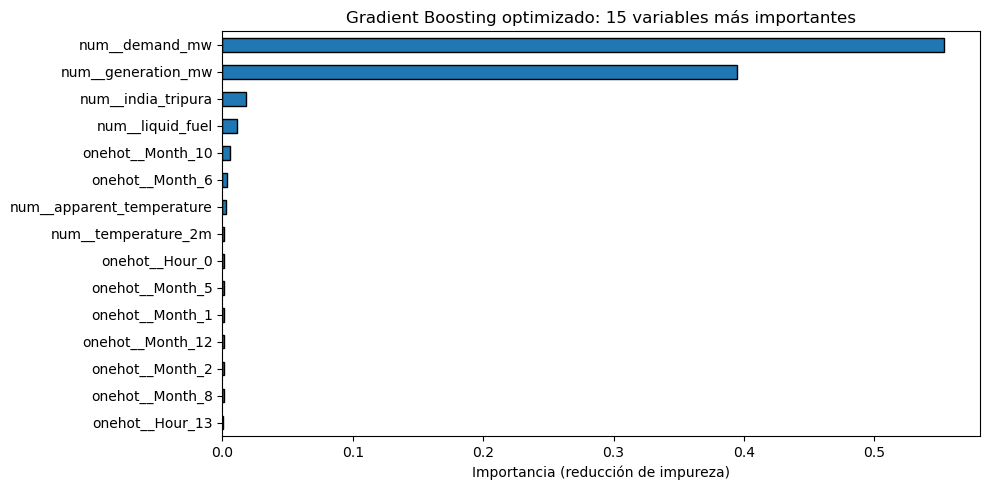

num__demand_mw               0.553
num__generation_mw           0.394
num__india_tripura           0.018
num__liquid_fuel             0.011
onehot__Month_10             0.006
onehot__Month_6              0.003
num__apparent_temperature    0.003
num__temperature_2m          0.002
onehot__Hour_0               0.001
onehot__Month_5              0.001
onehot__Month_1              0.001
onehot__Month_12             0.001
onehot__Month_2              0.001
onehot__Month_8              0.001
onehot__Hour_13              0.000
dtype: float64

In [22]:
feature_names = best_gb.named_steps["preprocessing"].get_feature_names_out()
importances = pd.Series(best_gb.named_steps["model"].feature_importances_, index=feature_names)
top = importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5))
top[::-1].plot(kind="barh", ax=ax, edgecolor="black")
ax.set_xlabel("Importancia (reducción de impureza)")
ax.set_title("Gradient Boosting optimizado: 15 variables más importantes")
plt.tight_layout()
plt.show()
top.round(3)

### Observaciones
- **Mejor configuración:** `learning_rate = 0.1`, `max_depth = 5`, `n_estimators = 300`, `subsample = 0.8`. RMSE CV de **133.85 ± 51.62 MW**, 19% menor que el Gradient Boosting por defecto y 21% menor que XGBoost.
- **Más árboles ayudan siempre:** las 6 mejores combinaciones usan 300 árboles. El óptimo está en el límite de la rejilla en `n_estimators` y `max_depth`, por lo que podría mejorar con más árboles.
- **`subsample = 0.8` es mejor que 1.0** en todos los pares de las 10 mejores combinaciones (133.9 frente a 138.6 MW): el muestreo aleatorio por árbol regulariza (*stochastic gradient boosting*).
- **Sobreajuste:** el RMSE de Train (27.2 MW) es 5 veces menor que el de validación. El modelo memoriza Train mucho más que el SVR (90.0 frente a 113.4 MW).
- **Costo:** la búsqueda tardó 127 s, frente a 107 s de AdaBoost.
- **Importancia de variables:** `demand_mw` (0.553) y `generation_mw` (0.394) concentran el 95% de la importancia. El modelo aprende, igual que el SVR lineal, que el load shedding es aproximadamente el déficit demanda − generación. El clima y el calendario aportan menos del 3%.

In [23]:
for name, model in [("AdaBoost optimizado", best_ada), ("Gradient Boosting optimizado", best_gb)]:
    evaluate_cv(name, model)

AdaBoost optimizado  (20.7 s)
  RMSE: 203.58 ± 41.65   (Train: 143.92)
  MAE:  134.18 ± 26.41
  R2:   0.604 ± 0.285
  RMSE por fold: [196.1 282.9 165.5 199.1 174.3]


Gradient Boosting optimizado  (18.9 s)
  RMSE: 133.85 ± 51.62   (Train: 27.24)
  MAE:  66.29 ± 25.64
  R2:   0.789 ± 0.230
  RMSE por fold: [166.8 211.5  97.9 129.2  63.9]


## Fase 7. Stacking

### 13. Construcción del ensamble
`StackingRegressor` entrena varios modelos base y un **meta-modelo** que aprende a combinar sus predicciones:
- **Modelos base:** SVR RBF optimizado, Gradient Boosting optimizado y AdaBoost optimizado. Son familias distintas (kernel frente a árboles; *boosting* por residuos frente a reponderación), por lo que sus errores no están perfectamente correlacionados.
- **Meta-modelo:** `LinearRegression(positive=True)`, una combinación lineal con pesos no negativos. Es simple y no sobreajusta con solo 3 entradas; los pesos se interpretan como la contribución de cada modelo.
- **Predicciones para el meta-modelo:** dentro de cada fold externo, `StackingRegressor` genera predicciones *out-of-fold* de los modelos base con `KFold(5, shuffle=False)`. No admite `TimeSeriesSplit` porque necesita una predicción para cada registro. Esto solo afecta al ajuste de los pesos del meta-modelo; la evaluación externa sigue siendo temporal y el bloque de validación nunca se usa para entrenar.

In [24]:
stacking = StackingRegressor(
    estimators=[
        ("svr", clone(best_svr)),
        ("gb", clone(best_gb)),
        ("ada", clone(best_ada)),
    ],
    final_estimator=LinearRegression(positive=True),
    cv=KFold(n_splits=5, shuffle=False),
    n_jobs=-1,
)
evaluate_cv("Stacking (SVR + GB + AdaBoost)", stacking)

Stacking (SVR + GB + AdaBoost)  (153.3 s)
  RMSE: 103.75 ± 38.89   (Train: 75.95)
  MAE:  40.46 ± 17.66
  R2:   0.864 ± 0.145
  RMSE por fold: [131.7 127.1  70.9 144.5  44.6]


In [25]:
stacking.fit(train_set_x, train_set_y)
meta = stacking.final_estimator_
print("Pesos del meta-modelo:", dict(zip(["SVR", "Gradient Boosting", "AdaBoost"], meta.coef_.round(3))))
print(f"Intercepto: {meta.intercept_:.2f}")

Pesos del meta-modelo: {'SVR': np.float64(0.73), 'Gradient Boosting': np.float64(0.293), 'AdaBoost': np.float64(0.0)}
Intercepto: -14.34


### Observaciones
- **RMSE CV = 103.75 ± 38.89 MW, MAE = 40.46 MW, R² = 0.864.** Es el mejor modelo de la práctica: 8.5% menos RMSE que el SVR RBF optimizado y 22.5% menos que el Gradient Boosting optimizado. Solo el Voting soft ponderado (Fase 7b) tiene una desviación entre folds algo menor (34.9 frente a 38.9 MW).
- **Mejora en 4 de 5 folds respecto al SVR.** En el fold 2 empata (127.1 MW) y en el fold 4 (144.5 MW) queda entre el SVR (161.6) y el Gradient Boosting (129.2).
- **Pesos del meta-modelo:** SVR 0.73, Gradient Boosting 0.29, AdaBoost 0.00, intercepto −14.3 MW.
  - El meta-modelo **descarta AdaBoost**: con `positive=True` le asigna peso 0 porque no aporta información que no tengan los otros dos.
  - El SVR domina, pero Gradient Boosting aporta lo suficiente para mejorar: sus errores son distintos (árboles con divisiones por umbral frente a un kernel suave).
  - Los pesos suman ≈ 1.02, por lo que el stacking es casi un promedio ponderado de los dos modelos.
- **Costo:** 153 s de validación cruzada, unas 26 veces más que el SVR solo. Cada fold externo entrena los 3 modelos base 6 veces (5 folds internos + el ajuste final).

## Fase 7b. Voting

### 13b. Construcción del ensamble
`VotingRegressor` entrena cada modelo base con todo el conjunto de entrenamiento del fold y combina sus predicciones con pesos **fijados de antemano**:

$$\hat{y}(x) = \sum_{k} w_k\, \hat{y}_k(x), \qquad \sum_k w_k = 1$$

- **Modelos base:** los mismos tres del stacking (SVR RBF, Gradient Boosting y AdaBoost optimizados), para que la comparación sea directa.
- **Diferencia con el stacking:** no hay meta-modelo ni predicciones *out-of-fold* internas, así que cada modelo base se entrena **una sola vez** por fold (en el stacking, 6 veces).
- **Variantes:**
  - **Soft, pesos iguales** ($w_k = 1/3$): promedio simple.
  - **Soft, ponderado por 1/MSE:** $w_k \propto 1/\text{RMSE}_{CV,k}^2$, con el RMSE de CV de cada modelo base en Train (Fase 6). Da más peso a los modelos más precisos sin usar Test.
  - **Hard (mediana):** análogo en regresión del *hard voting*; ver 13c.


In [26]:
base_models = [("svr", best_svr), ("gb", best_gb), ("ada", best_ada)]
base_names = {"svr": "SVR RBF optimizado", "gb": "Gradient Boosting optimizado", "ada": "AdaBoost optimizado"}

voting_soft = VotingRegressor([(name, clone(model)) for name, model in base_models], n_jobs=-1)
evaluate_cv("Voting soft (pesos iguales)", voting_soft)

# Pesos inversamente proporcionales al MSE de CV de cada modelo base (solo Train)
inverse_mse = np.array([1 / (-cv_results[base_names[name]]["test_rmse"].mean()) ** 2 for name, _ in base_models])
voting_weights = inverse_mse / inverse_mse.sum()
print("Pesos 1/MSE:", dict(zip(["SVR", "Gradient Boosting", "AdaBoost"], voting_weights.round(3))))

voting_weighted = VotingRegressor(
    [(name, clone(model)) for name, model in base_models], weights=voting_weights, n_jobs=-1,
)
evaluate_cv("Voting soft ponderado (1/MSE)", voting_weighted)


Voting soft (pesos iguales)  (37.6 s)
  RMSE: 123.43 ± 36.14   (Train: 65.48)
  MAE:  71.61 ± 13.34
  R2:   0.833 ± 0.165
  RMSE por fold: [143.2 178.3  91.7 126.5  77.5]
Pesos 1/MSE: {'SVR': np.float64(0.493), 'Gradient Boosting': np.float64(0.354), 'AdaBoost': np.float64(0.153)}


Voting soft ponderado (1/MSE)  (33.6 s)
  RMSE: 106.94 ± 34.95   (Train: 57.94)
  MAE:  55.07 ± 13.67
  R2:   0.865 ± 0.144
  RMSE por fold: [132.2 149.   76.1 120.9  56.4]


### 13c. Soft voting frente a hard voting
En clasificación, `VotingClassifier` ofrece dos modos:
- **Hard voting:** cada modelo vota por una clase y gana la **mayoría**.
- **Soft voting:** se promedian las **probabilidades** y gana la clase con mayor probabilidad promedio.

`VotingRegressor` no tiene parámetro `voting`: siempre promedia. En regresión se usa su análogo:

| | Clasificación | Regresión (esta práctica) |
|---|---|---|
| **Soft** | promedio de probabilidades | **media** de las predicciones, $\hat{y} = \frac{1}{K}\sum_k \hat{y}_k$ |
| **Hard** | moda de las clases votadas | **mediana** de las predicciones, $\hat{y} = \operatorname{mediana}(\hat{y}_1,\dots,\hat{y}_K)$ |

- La **mediana** es el "voto mayoritario" de un valor continuo: es robusta a un modelo que se aleja de los demás, pero ignora *cuánto* se aleja (igual que el hard voting ignora la confianza).
- La **media** usa toda la magnitud de cada predicción (igual que el soft voting usa las probabilidades completas).
- Con 3 modelos, la mediana es, en cada hora, **la predicción del modelo intermedio**: descarta la más alta y la más baja.


In [27]:
class HardVotingRegressor(VotingRegressor):
    """Análogo de hard voting para regresión: mediana de las predicciones de los modelos base."""

    def predict(self, X):
        # transform() devuelve una columna por modelo base: (n_registros, n_modelos)
        return np.median(self.transform(X), axis=1)


voting_hard = HardVotingRegressor([(name, clone(model)) for name, model in base_models], n_jobs=-1)
evaluate_cv("Voting hard (mediana)", voting_hard)

voting_names = ["Stacking (SVR + GB + AdaBoost)", "Voting soft (pesos iguales)",
                "Voting soft ponderado (1/MSE)", "Voting hard (mediana)"]
display(summarize({name: cv_results[name] for name in voting_names}))

voting_fold_rmse = pd.DataFrame(
    {name: -cv_results[name]["test_rmse"] for name in ["SVR RBF optimizado"] + voting_names},
    index=[f"Fold {i}" for i in range(1, 6)],
)
voting_fold_rmse["Soft − Hard"] = voting_fold_rmse["Voting soft (pesos iguales)"] - voting_fold_rmse["Voting hard (mediana)"]
voting_fold_rmse.round(1)


Voting hard (mediana)  (33.7 s)
  RMSE: 125.11 ± 51.59   (Train: 35.51)
  MAE:  61.96 ± 20.90
  R2:   0.818 ± 0.202
  RMSE por fold: [156.1 204.6  85.5 121.   58.4]


,RMSE,RMSE std,MAE,MAE std,R2,R2 std,RMSE Train
Modelo,,,,,,,
Stacking (SVR + GB + AdaBoost),103.748,38.890,40.462,17.662,0.864,0.145,75.954
Voting soft (pesos iguales),123.434,36.138,71.612,13.344,0.833,0.165,65.476
Voting soft ponderado (1/MSE),106.940,34.946,55.072,13.669,0.865,0.144,57.937
Voting hard (mediana),125.112,51.595,61.964,20.901,0.818,0.202,35.505


,SVR RBF optimizado,Stacking (SVR + GB + AdaBoost),Voting soft (pesos iguales),Voting soft ponderado (1/MSE),Voting hard (mediana),Soft − Hard
Fold 1,152.1,131.7,143.2,132.2,156.1,-12.9
Fold 2,127.1,127.1,178.3,149.0,204.6,-26.3
Fold 3,75.7,70.9,91.7,76.1,85.5,6.2
Fold 4,161.6,144.5,126.5,120.9,121.0,5.6
Fold 5,50.6,44.6,77.5,56.4,58.4,19.0


In [28]:
# ¿Qué modelo queda en la mediana (el que el hard voting elige) y cuáles descarta? Predicciones en Train.
voting_hard.fit(train_set_x, train_set_y)
base_train_predictions = pd.DataFrame(
    voting_hard.transform(train_set_x), columns=[base_names[name] for name, _ in base_models],
)
median_model = base_train_predictions.rank(axis=1, method="first").eq(2).idxmax(axis=1)
pd.DataFrame({
    "% veces mediana (elegido)": median_model.value_counts(normalize=True) * 100,
    "% veces máximo (descartado)": base_train_predictions.idxmax(axis=1).value_counts(normalize=True) * 100,
    "% veces mínimo (descartado)": base_train_predictions.idxmin(axis=1).value_counts(normalize=True) * 100,
}).reindex(base_names.values()).fillna(0).round(1)


,% veces mediana (elegido),% veces máximo (descartado),% veces mínimo (descartado)
SVR RBF optimizado,52.4,21.8,25.8
Gradient Boosting optimizado,37.4,14.0,48.5
AdaBoost optimizado,10.2,64.2,25.7


### Observaciones (Voting)
- **Resultados en CV:**
  - **Soft ponderado (1/MSE): RMSE 106.94 ± 34.95 MW, MAE 55.07, R² 0.865.** Es el mejor voting y queda a solo 3.1% del stacking (103.75). Mejora al SVR (113.42) en 4 de 5 folds; solo pierde en el fold 2 (149.0 frente a 127.1).
  - **Soft con pesos iguales: 123.43 ± 36.14 MW.** Peor que el SVR solo (+8.8%): con $w = 1/3$, AdaBoost (203.6 MW en CV) arrastra el promedio.
  - **Hard (mediana): 125.11 ± 51.59 MW.** Prácticamente empatado con el soft de pesos iguales, pero con la mayor desviación entre folds.
- **Pesos 1/MSE:** SVR 0.49, Gradient Boosting 0.35, AdaBoost 0.15. El orden coincide con el del stacking (0.73 / 0.29 / 0.00), pero el voting no puede anular a AdaBoost: un peso fijo según la precisión individual siempre es positivo, aunque el modelo sea redundante.
- **Soft frente a hard (pesos iguales):** el hard gana en los folds 3, 4 y 5 (por 5.6 a 19.0 MW) y pierde en los folds 1 y 2 (por 12.9 y 26.3 MW). En promedio empatan (123.4 frente a 125.1).
- **Qué elige la mediana** (predicciones en Train):
  - El **SVR** es la predicción intermedia en el 52.4% de las horas y **Gradient Boosting** en el 37.4%. **AdaBoost** solo en el 10.2%.
  - **AdaBoost es el máximo en el 64.2% de las horas**: sobreestima de forma sistemática y la mediana lo descarta casi siempre. Esa es la ventaja del hard voting: es robusto a un modelo que se aleja de los demás, sin tener que conocer su calidad.
  - **Gradient Boosting es el mínimo en el 48.5%** de las horas.
- **Brecha Train–CV:** el hard tiene el menor RMSE de Train de los voting (35.5 MW frente a 65.5 del soft): cuando la mediana elige a Gradient Boosting hereda su sobreajuste (27.2 MW en Train).
- **Costo:** 34–38 s de validación cruzada por variante, unas 4 veces menos que el stacking (153 s). Cada modelo base se entrena una sola vez por fold.


### 14. Comparación en validación cruzada

In [29]:
cv_table = summarize(cv_results).sort_values("RMSE")
cv_table

,RMSE,RMSE std,MAE,MAE std,R2,R2 std,RMSE Train
Modelo,,,,,,,
Stacking (SVR + GB + AdaBoost),103.748,38.890,40.462,17.662,0.864,0.145,75.954
Voting soft ponderado (1/MSE),106.940,34.946,55.072,13.669,0.865,0.144,57.937
SVR RBF optimizado,113.424,43.299,46.248,23.364,0.827,0.196,90.035
Voting soft (pesos iguales),123.434,36.138,71.612,13.344,0.833,0.165,65.476
Voting hard (mediana),125.112,51.595,61.964,20.901,0.818,0.202,35.505
Gradient Boosting optimizado,133.850,51.619,66.294,25.638,0.789,0.230,27.240
Gradient Boosting,165.495,54.938,94.923,31.341,0.707,0.265,108.817
XGBoost (max_depth=5),168.943,67.209,95.203,37.782,0.702,0.263,55.574
AdaBoost optimizado,203.576,41.651,134.178,26.413,0.604,0.285,143.915


### Observaciones
- **Ranking en CV:** Stacking (103.7) < Voting soft ponderado (106.9) < SVR RBF optimizado (113.4) < Voting soft pesos iguales (123.4) < Voting hard (125.1) < Gradient Boosting optimizado (133.9) < Gradient Boosting (165.5) < XGBoost (168.9) < AdaBoost optimizado (203.6) < AdaBoost (469.8) < Dummy (489.9).
- **Modelo seleccionado:** Stacking, por tener el menor RMSE CV. Es también el de menor MAE (40.5 MW). El Voting soft ponderado tiene un R² ligeramente mayor (0.865 frente a 0.864), pero un MAE 36% mayor (55.1 MW).
- **Solo el voting ponderado supera al SVR:** los dos voting con pesos iguales (soft y hard) quedan por encima del SVR solo. Sin pesos aprendidos o ajustados, combinar el mejor modelo con uno mucho peor (AdaBoost) empeora el resultado.
- **Sesgo–varianza:** el Gradient Boosting optimizado tiene el menor RMSE de Train (27.2 MW) pero no el menor de validación: es el modelo con más varianza. El stacking tiene un RMSE de Train intermedio (76.0 MW): combina la baja varianza del SVR con el menor sesgo del Gradient Boosting.


# V. Evaluación final

## Fase 8. Evaluación final en Test

### 15. Evaluación de los modelos
Primer uso de Test. El modelo seleccionado es el de menor RMSE CV; los demás se evalúan en Test **solo para la discusión**. Todos se reentrenan en todo Train.

In [30]:
final_models = {
    "Linear Regression": make_linear(LinearRegression()),
    ridge_name: best_ridge,
    poly_name: best_poly,
    "SVR Lineal": make_svr(kernel="linear"),
    "SVR RBF optimizado": best_svr,
    "XGBoost (max_depth=5)": xgb_model,
    "AdaBoost optimizado": best_ada,
    "Gradient Boosting optimizado": best_gb,
    "Stacking (SVR + GB + AdaBoost)": stacking,
    "Voting soft (pesos iguales)": voting_soft,
    "Voting soft ponderado (1/MSE)": voting_weighted,
    "Voting hard (mediana)": voting_hard,
}
test_predictions = {}
for name, model in final_models.items():
    test_predictions[name] = pd.Series(model.fit(train_set_x, train_set_y).predict(test_set_x), index=test_set_y.index)

rows = []
for name, pred in test_predictions.items():
    s = cv_results[name]
    rows.append({
        "Modelo": name,
        "RMSE CV": -s["test_rmse"].mean(),
        "R2 CV": s["test_r2"].mean(),
        "RMSE Test": np.sqrt(mean_squared_error(test_set_y, pred)),
        "MAE Test": mean_absolute_error(test_set_y, pred),
        "R2 Test": r2_score(test_set_y, pred),
        "% ŷ < 0": (pred < 0).mean() * 100,
    })
final_comparison = pd.DataFrame(rows).set_index("Modelo").sort_values("RMSE CV").round(2)
final_comparison

,RMSE CV,R2 CV,RMSE Test,MAE Test,R2 Test,% ŷ < 0
Modelo,,,,,,
Stacking (SVR + GB + AdaBoost),103.75,0.86,45.30,28.71,0.75,33.04
Voting soft ponderado (1/MSE),106.94,0.87,66.29,45.39,0.46,14.70
SVR RBF optimizado,113.42,0.83,50.76,33.22,0.68,20.76
Voting soft (pesos iguales),123.43,0.83,90.14,61.55,-0.01,10.08
Voting hard (mediana),125.11,0.82,64.71,40.87,0.48,8.83
Gradient Boosting optimizado,133.85,0.79,66.04,36.31,0.46,16.24
XGBoost (max_depth=5),168.94,0.70,75.01,44.06,0.30,24.76
AdaBoost optimizado,203.58,0.60,184.89,124.89,-3.24,0.00


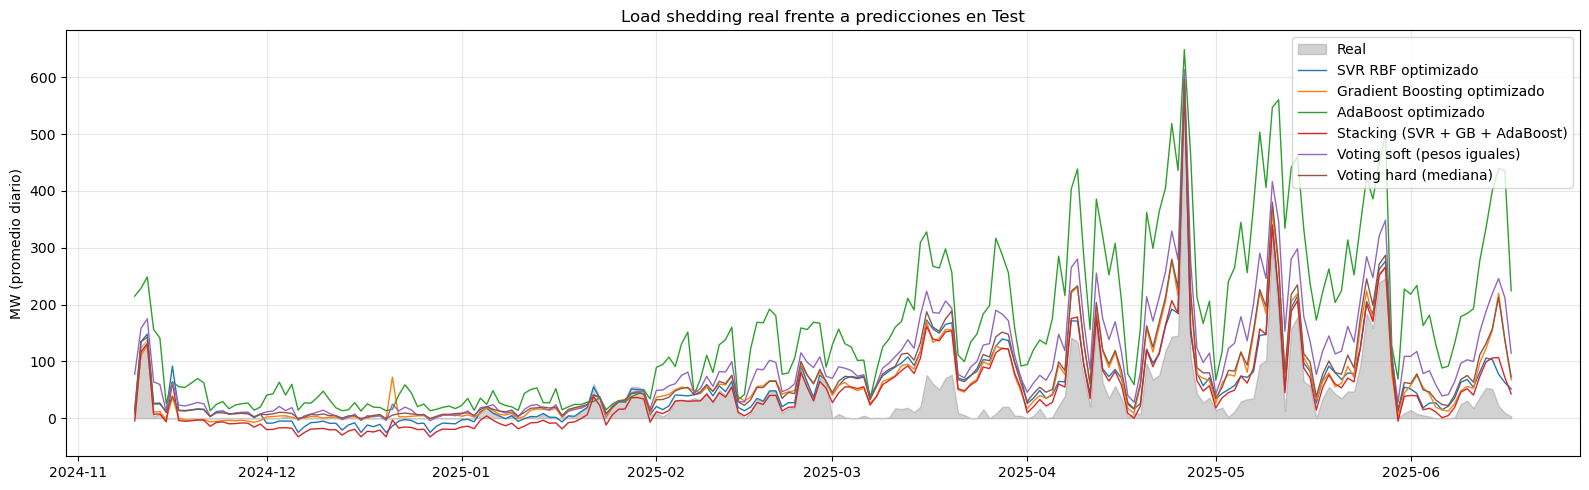

In [31]:
test_daily = pd.DataFrame(
    {"Real": test_set_y, **test_predictions}
).groupby(test_set_x["datetime"].dt.date).mean()
test_daily.index = pd.to_datetime(test_daily.index)

fig, ax = plt.subplots(figsize=(16, 5))
ax.fill_between(test_daily.index, test_daily["Real"], color="gray", alpha=0.35, label="Real")
for name in [ridge_name, "SVR Lineal", "SVR RBF optimizado", "Gradient Boosting optimizado", "AdaBoost optimizado", "Stacking (SVR + GB + AdaBoost)",
             "Voting soft (pesos iguales)", "Voting hard (mediana)"]:
    ax.plot(test_daily.index, test_daily[name], linewidth=1, label=name)
ax.set_ylabel("MW (promedio diario)")
ax.set_title("Load shedding real frente a predicciones en Test")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
ranges = pd.cut(test_set_y, [-np.inf, 0, 100, 300, 750, np.inf], labels=["0", "1-100", "100-300", "300-750", ">750"])
residuals = pd.DataFrame({name: test_set_y - pred for name, pred in test_predictions.items()})
residuals.groupby(ranges, observed=True).mean().round(1).assign(registros=ranges.value_counts().sort_index())

,SVR RBF optimizado,XGBoost (max_depth=5),AdaBoost optimizado,Gradient Boosting optimizado,Stacking (SVR + GB + AdaBoost),Voting soft (pesos iguales),Voting soft ponderado (1/MSE),Voting hard (mediana),registros
load_shedding,,,,,,,,,
0,-20.3,-24.6,-87.9,-25.6,-8.0,-44.6,-32.6,-31.5,3588
1-100,-29.5,-45.4,-167.5,-38.7,-19.8,-78.6,-53.9,-47.4,1345
100-300,-34.8,-71.1,-248.6,-53.4,-30.5,-112.3,-74.1,-66.9,450
300-750,-11.3,-15.9,-166.4,-7.7,-5.6,-61.8,-33.8,-30.3,68
>750,85.5,148.8,380.6,32.8,45.2,166.3,112.0,86.5,6


### Observaciones
- **Ranking en Test:** Stacking (RMSE 45.30, MAE 28.71, R² 0.75) < SVR RBF optimizado (50.76, 33.22, 0.68) < Voting hard (64.71, 40.87, 0.48) < Gradient Boosting optimizado (66.04, 36.31, 0.46) ≈ Voting soft ponderado (66.29, 45.39, 0.46) < XGBoost (75.01) < Voting soft pesos iguales (90.14, R² −0.01) < AdaBoost optimizado (184.89).
- **El stacking y el SVR conservan los dos primeros lugares**, pero los voting cambian de posición respecto a CV:
  - El **Voting soft ponderado**, segundo en CV, cae al quinto lugar en Test: 30.6% más RMSE que el SVR.
  - El **Voting hard** pasa del quinto lugar en CV al tercero en Test, por delante de los dos soft.
- **El stacking mejora al SVR en Test:** 10.8% menos RMSE, 13.6% menos MAE y R² de 0.68 a 0.75.
- **Cambio de régimen:** igual que en `LoadSheddingSVR.ipynb`, el RMSE de Test es menor que el de CV porque el load shedding de 2025 tiene un nivel y una varianza mucho menores (media de 33.4 frente a 320.6 MW). Las comparaciones válidas son entre modelos, no entre CV y Test.
- **AdaBoost colapsa en Test (R² = −3.24):** sobreestima en todos los rangos bajos (de −88 MW cuando el real es 0 a −249 MW en 100–300) y nunca predice valores negativos. La mediana ponderada de árboles entrenados con el régimen alto de 2023–2024 no se adapta al régimen bajo de 2025.
- **Por qué fallan los voting en Test:** heredan el colapso de AdaBoost en proporción a su peso fijo.
  - **Soft pesos iguales** ($w = 1/3$): sobreestima −44.6 MW cuando el real es 0 y −112.3 MW en 100–300. Su R² de Test es prácticamente 0.
  - **Soft ponderado** ($w = 0.15$): el sesgo se reduce (−32.6 MW cuando el real es 0), pero sigue por encima del SVR (−20.3).
  - **Hard (mediana):** descarta a AdaBoost cuando es el máximo, por eso es el más robusto de los tres voting (−31.5 MW cuando el real es 0). Aun así no alcanza al SVR solo.
  - El **stacking** no tiene este problema porque su meta-modelo asignó peso 0 a AdaBoost.
- **Residuos por rango:** el stacking tiene el menor sesgo en los rangos bajos (−8.0 MW cuando el real es 0, frente a −20.3 del SVR), donde están el 66% de las horas de Test. En los 6 eventos > 750 MW el Gradient Boosting tiene menos sesgo (+32.8 MW) que el stacking (+45.2) y el SVR (+85.5). Los voting son los que más subestiman los picos después de AdaBoost y XGBoost: de +86.5 (hard) a +166.3 MW (soft pesos iguales).
- **Predicciones negativas:** el stacking produce más (33.0%) que el SVR (20.8%) porque el intercepto del meta-modelo (−14.3 MW) desplaza hacia abajo las horas con predicción cercana a 0. Los voting producen menos (8.8% a 14.7%) porque promedian con AdaBoost, que nunca predice valores negativos. Recortar las predicciones a 0 MW, el valor físicamente posible, es una corrección sencilla de posprocesamiento.


## Fase 9. Discusión de resultados

### 16. Preguntas de discusión

| Modelo | RMSE CV | R² CV | RMSE Test | MAE Test | R² Test |
|---|---|---|---|---|---|
| **Stacking (SVR + GB + AdaBoost)** | **103.75** | **0.86** | **45.30** | **28.71** | **0.75** |
| SVR RBF optimizado (C = 100, γ = 0.01) | 113.42 | 0.83 | 50.76 | 33.22 | 0.68 |
| Gradient Boosting optimizado | 133.85 | 0.79 | 66.04 | 36.31 | 0.46 |
| XGBoost (práctica anterior) | 168.94 | 0.70 | 75.01 | 44.06 | 0.30 |
| AdaBoost optimizado | 203.58 | 0.60 | 184.89 | 124.89 | −3.24 |
| Voting soft ponderado (1/MSE) | 106.94 | 0.87 | 66.29 | 45.39 | 0.46 |
| Voting soft (pesos iguales) | 123.43 | 0.83 | 90.14 | 61.55 | −0.01 |
| Voting hard (mediana) | 125.11 | 0.82 | 64.71 | 40.87 | 0.48 |

- **¿Los ensambles mejoran al SVR?**
  - Los ensambles de *boosting* por sí solos, no: el mejor (Gradient Boosting optimizado) queda 18% por encima del SVR en RMSE CV y 30% en Test.
  - El **stacking** sí mejora, en CV (−8.5%) y en Test (−10.8%), porque combina dos modelos con errores distintos.
  - El **voting** solo mejora al SVR en CV, y solo con pesos 1/MSE (−5.7%). En Test ninguna variante lo supera.
- **¿Por qué el stacking supera al voting si usan los mismos modelos base?**
  - El meta-modelo **aprende** los pesos a partir de predicciones *out-of-fold* y puede anular un modelo redundante (AdaBoost = 0).
  - El voting fija los pesos de antemano: con pesos iguales o 1/MSE, AdaBoost siempre recibe un peso positivo y su colapso en Test se transmite al ensamble.
  - El **hard voting** (mediana) es un punto intermedio: no aprende pesos, pero descarta en cada hora la predicción extrema, que casi siempre es la de AdaBoost. Por eso es el mejor voting en Test.
- **¿Por qué AdaBoost es tan inferior a Gradient Boosting si ambos son boosting?**
  - AdaBoost cambia los **pesos de las muestras** según su error relativo, y un puñado de registros anómalos (o de picos de load shedding) acapara el peso del entrenamiento.
  - Gradient Boosting ajusta los **residuos** con pasos pequeños; un registro anómalo solo afecta a las hojas donde cae.
  - En un problema con 41.6% de ceros, distribución muy asimétrica y entradas erróneas, la reponderación es el mecanismo menos robusto.
- **¿El incremento de complejidad se justifica?**
  - El stacking cuesta unas 26 veces más tiempo de entrenamiento que el SVR para una mejora de ~10 MW en RMSE.
  - Para un modelo que se reentrena fuera de línea, el costo es aceptable.
  - Si se prefiere simplicidad, el SVR RBF optimizado sigue siendo una alternativa muy cercana con un solo modelo.
- **¿Test es consistente con CV?** Para los modelos individuales y el stacking, sí: su orden es el mismo en CV y en Test. Los voting no: el soft ponderado pasa del 2.º al 5.º lugar y el hard del 5.º al 3.º, porque su resultado depende de cómo se comporta AdaBoost con el régimen de 2025.
- **Limitación compartida:** `demand_mw` y `generation_mw` concentran el 95% de la importancia en Gradient Boosting y se miden en la misma hora que el objetivo. Todos los modelos son de *nowcasting*, no de pronóstico.

# VI. Conclusiones

- **Stacking es el mejor modelo:** RMSE CV de 103.75 MW y RMSE Test de 45.30 MW (R² = 0.75), mejor que el SVR RBF optimizado (113.42 / 50.76 MW) y que todos los ensambles de árboles.
- **El valor del stacking está en la diversidad:** el meta-modelo asigna 0.73 al SVR, 0.29 al Gradient Boosting y 0 a AdaBoost. Combinar un kernel suave con árboles de divisiones por umbral reduce el error; añadir un modelo débil y redundante no aporta nada.
- **Voting:** sin meta-modelo, la calidad depende de los pesos fijos. El soft ponderado (1/MSE) casi iguala al stacking en CV (106.9 MW), pero en Test queda por debajo del SVR (66.3 MW) porque mantiene un 15% de peso para AdaBoost. El **hard (mediana)** es el voting más robusto en Test (64.7 MW): descarta la predicción extrema de AdaBoost en cada hora. Ninguna variante supera al stacking.
- **Gradient Boosting:** con optimización (300 árboles, `max_depth = 5`, `subsample = 0.8`) mejora 19% respecto a sus valores por defecto y supera a XGBoost, pero sobreajusta (RMSE de Train de 27 MW) y no alcanza al SVR por sí solo.
- **AdaBoost no es adecuado para este problema:** la reponderación de muestras amplifica el efecto de los registros anómalos y de los picos. Incluso optimizado (203.6 MW en CV) colapsa en Test (R² = −3.24).
- **Todos los modelos aprenden el déficit demanda − generación** como la señal principal, lo que confirma la conclusión de la práctica de SVR.
- **Trabajo futuro:**
  - Limpiar con una regla fija los registros con demanda o generación por debajo de un mínimo físico. Probablemente beneficiaría sobre todo a AdaBoost.
  - Ampliar la rejilla de Gradient Boosting (más árboles, `min_samples_leaf`) y probar `HistGradientBoostingRegressor`, mucho más rápido.
  - Recortar a 0 las predicciones negativas del stacking y usar variables rezagadas para pasar de *nowcasting* a pronóstico.

# VII. Referencias

- Power Grid Company of Bangladesh. *PGCB Hourly Generation Dataset (Bangladesh)*. UCI Machine Learning Repository.
- Open-Meteo. *Historical Weather API*. https://open-meteo.com/en/docs/historical-weather-api
- Freund, Y., & Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, 55(1), 119–139.
- Drucker, H. (1997). Improving regressors using boosting techniques. *Proceedings of the 14th International Conference on Machine Learning (ICML)*, 107–115.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.
- Friedman, J. H. (2002). Stochastic gradient boosting. *Computational Statistics & Data Analysis*, 38(4), 367–378.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
- Breiman, L. (1996). Stacked regressions. *Machine Learning*, 24(1), 49–64.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD*, 785–794.
- scikit-learn developers. *Ensembles: Gradient boosting, random forests, bagging, voting, stacking*. https://scikit-learn.org/stable/modules/ensemble.html
- Géron, A. (2019). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (2.ª ed.), cap. 7 "Ensemble Learning and Random Forests". O'Reilly.
- Rodríguez Pacheco, A. G. *LoadSheddingSVR.ipynb* — Práctica de Support Vector Regression sobre el mismo dataset.